In [4]:
import numpy as np
import sympy as sym
from sympy import symbols, Eq, pprint, init_printing
import matplotlib.pyplot as plt
# import tellurium as te
from IPython.display import display
sym.init_printing()
from scipy.integrate import odeint
import json

### Cohesive network [PDS5, Wapl, Sororin, unloading]

In [ ]:
## Rates for cohesive network 
rates_coh = sym.symbols("K_Rac_RacP, K_RacP_Rac, K_RacP_RacPW, K_RacPW_RacP, K_RacP_RacPS, K_RacPS_RacP, K_RacPW_Rac_free")
K_Rac_RacP, K_RacP_Rac, K_RacP_RacPW, K_RacPW_RacP, K_RacP_RacPS, K_RacPS_RacP, K_RacPW_Rac_free = rates_coh

parameters_coh = sym.symbols("tau_S, F_S, N_S, tau_W, F_W, N_W, tau_P, F_P, N_P, tau_R, F_R_sister, N_R")
tau_S, F_S, N_S, tau_W, F_W, N_W, tau_P, F_P, N_P, tau_R, F_R_sister, N_R = parameters_coh 

## Equations for cohesive network
rhs_coh = [ K_RacPW_Rac_free * N_W * F_W - F_R_sister*N_R/tau_R,              # RAD21 unbinding 
        F_W/(tau_W * (1-F_W)) - K_RacP_RacPW*(F_P*N_P - F_S*N_S - F_W*N_W),   # Wapl binding 
        K_RacPW_RacP + K_RacPW_Rac_free - 1/tau_W,                            # Wapl unbinding  
        F_S/(tau_S * (1-F_S)) - K_RacP_RacPS * (F_P*N_P - F_S*N_S - F_W*N_W), # Sororin binding
        K_RacPS_RacP - 1/tau_S,                                               # Sororin unbinding
        F_P/(tau_P * (1-F_P)) - K_Rac_RacP * (F_R_sister*N_R - F_P * N_P),    # PDS5 binding
        K_RacPW_Rac_free * F_W *N_W + K_RacP_Rac*(F_P*N_P - F_S*N_S - F_W*N_W) - F_P*N_P/tau_P,   # PDS5 unbinding  
]

## Solutions for cohesive network
sol_rates_coh = sym.solve(rhs_coh, rates_coh)

for i, eq in enumerate(rhs_coh, 1):
    pprint(Eq(symbols(f"eq_{i}"), eq))

        F_R_sister⋅N_R                           
eq₁ = - ────────────── + F_W⋅K_RacPW_Rac_free⋅N_W
             τ_R                                 
           F_W                                                  
eq₂ = ───────────── - K_RacP_RacPW⋅(F_P⋅N_P - F_S⋅N_S - F_W⋅N_W)
      τ_W⋅(1 - F_W)                                             
                                         1 
eq₃ = K_RacPW_RacP + K_RacPW_Rac_free - ───
                                        τ_W
           F_S                                                  
eq₄ = ───────────── - K_RacP_RacPS⋅(F_P⋅N_P - F_S⋅N_S - F_W⋅N_W)
      τ_S⋅(1 - F_S)                                             
                      1 
eq₅ = K_RacPS_RacP - ───
                     τ_S
           F_P                                              
eq₆ = ───────────── - K_Rac_RacP⋅(-F_P⋅N_P + F_R_sister⋅N_R)
      τ_P⋅(1 - F_P)                                         
        F_P⋅N_P                                                       

In [6]:
with open("parameters_12h.json", "r") as f:
    PARAMS = json.load(f)

In [19]:
def get_parameter_dict_coh(x, y):
    p = PARAMS["cohesive"]
    parameter_values_coh = [
        p["tau_S"],
        p["F_S"],
        p["N_S"],
        p["tau_W"],
        x / (p["x_offset_W"] + x),                        # modified F_W for sister
        p["N_W_base"] * (p["x_offset_W"] + x),            # modified N_W for sister
        p["tau_P"],
        y / (p["y_offset_P"] + y),                        # modified F_P for sister
        p["N_P_base"] * (p["y_offset_P"] + y),            # modified N_P for sister
        p["tau_R_sister"],
        p["F_R_sister"],
        p["N_R_modify"],                                 
    ]
    return dict(zip(parameters_coh, parameter_values_coh))

In [53]:
parameter_dict_coh = get_parameter_dict_coh(0.12028, 0.30274)
parameter_dict_coh

In [56]:
parameter_dict_coh_dS = get_parameter_dict_coh(0.12028, 0.30274)
parameter_dict_coh_dS[N_S] *= 0.03

for s in sol_rates_coh.items():
    rate_dS = s[1].evalf(subs=parameter_dict_coh_dS)
    parameter_dict_coh_dS[s[0]] = rate_dS
parameter_dict_coh_dS

In [42]:
rate_names = [
    K_Rac_RacP,
    K_RacP_Rac,
    K_RacP_RacPS,
    K_RacPS_RacP,
    K_RacP_RacPW,
    K_RacPW_RacP,
    K_RacPW_Rac_free
]

In [44]:
# Which rates should be divided by 20: the association rates 
times_20 = {K_Rac_RacP, K_RacP_RacPS, K_RacP_RacPW}
# Collect rates in the correct order, dividing where needed
rates_scale = np.array([
    float(sol_rates_coh[name].evalf(subs=parameter_dict_coh)) * (20 if name in times_20 else 1)
    for name in rate_names
])
# print for checking
for name, val in zip(rate_names, rates_scale):
    print(f"{str(name):20s} {val:.6e}")

K_Rac_RacP           3.611763e-06
K_RacP_Rac           1.566336e-01
K_RacP_RacPS         4.481702e-05
K_RacPS_RacP         1.000000e-02
K_RacP_RacPW         1.701173e-05
K_RacPW_RacP         2.195981e-02
K_RacPW_Rac_free     2.624163e-04


In [38]:
# Which rates should be divided by 20
times_20 = {K_Rac_RacP, K_RacP_RacPS, K_RacP_RacPW}
# Collect rates in the correct order, dividing where needed
rates_dS = np.array([
    float(sol_rates_coh[name].evalf(subs=parameter_dict_coh_dS)) * (20 if name in times_20 else 1)
    for name in rate_names
])
# print for checking
for name, val in zip(rate_names, rates_dS):
    print(f"{str(name):20s} {val:.6e}")

K_Rac_RacP           3.611763e-06
K_RacP_Rac           1.680127e-02
K_RacP_RacPS         4.807288e-06
K_RacPS_RacP         1.000000e-02
K_RacP_RacPW         1.824759e-06
K_RacPW_RacP         2.195981e-02
K_RacPW_Rac_free     2.624163e-04


### Gillespie Simulation -- population level

In [40]:
def gillespie_simulation(rates, stoich_matrix, initial_state, t_max, max_steps = 1e8):
    """
    Gillespie algorithm implementation with bounds checking
    """
    # Initialize
    state = np.array(initial_state, dtype=int)
    time = 0.0
    # Storage
    times = [0.0]
    states = [state.copy()]
    step = 0
    rejected_reactions = 0
    while time < t_max and step < max_steps:
        # Calculate propensities
        props = calculate_propensities(state, rates)
        prop_sum = np.sum(props)
        # Sample time to next reaction
        tau = np.random.exponential(1.0 / prop_sum)
        time += tau
        # Sample which reaction occurs
        reaction = np.random.choice(len(props), p = props/prop_sum)
        # Check if reaction can occur (prevents negative values)
        new_state = state + stoich_matrix[reaction]
        # Skip reaction if it would create negative species
        if np.any(new_state < 0):
            rejected_reactions += 1
            continue
        # Update state (only if reaction is valid)
        state = new_state
        # Store the time and states 
        times.append(time)
        states.append(state.copy())
        step += 1
    print(f"Rejected {rejected_reactions} invalid reactions")
    return np.array(times), np.array(states)

def calculate_propensities(state, rates):
    """Calculate reaction propensities for Rac network"""
    Rac_free, Rac, RacP, RacPW, RacPS, S, W, P = state
    
    props = np.array([
        rates[0] * Rac * P,           # R1: Rac + P -> RacP
        rates[1] * RacP,              # R2: RacP -> Rac + P  
        rates[2] * RacP * S,          # R3: RacP + S -> RacPS
        rates[3] * RacPS,             # R4: RacPS -> RacP + S
        rates[4] * RacP * W,          # R5: RacP + W -> RacPW
        rates[5] * RacPW,             # R6: RacPW -> RacP + W
        rates[6] * RacPW              # R7: RacPW -> Rac_free + P + W
    ])
    return np.maximum(props, 0)       # Ensure non-negative


def ode_system(y, t, rates, stoich_matrix):
    """ODE system for comparison with stochastic simulation"""
    props = calculate_propensities(y, rates)
    dydt = np.dot(stoich_matrix.T, props)
    return dydt

In [ ]:
rates_original = np.array([
    0.00000263392746473637,  # K_Rac_RacP
    0.0215847000671363,          # K_RacP_Rac  
    1.87677933117359E-7,     # K_RacP_RacPS
    0.0100000000000000,          # K_RacPS_RacP
    5.92277500962081E-8,     # K_RacP_RacPW
    0.0211261475150364,          # K_RacPW_RacP
    0.00109607470718582          # K_RacPW_Rac_free
])

In [ ]:
# Set up simulation, reaction rates 
rates = np.array([
    0.00000263392746473637*100,  # K_Rac_RacP
    0.0215847000671363,          # K_RacP_Rac  
    1.87677933117359E-7*100,     # K_RacP_RacPS
    0.0100000000000000,          # K_RacPS_RacP
    5.92277500962081E-8*100,     # K_RacP_RacPW
    0.0211261475150364,          # K_RacPW_RacP
    0.00109607470718582          # K_RacPW_Rac_free
])


In [45]:
rates_scale

array([3.61176286e-06, 1.56633591e-01, 4.48170155e-05, 1.00000000e-02,
       1.70117258e-05, 2.19598059e-02, 2.62416341e-04])

In [52]:
# Stoichiometry matrix (reactions x species)
# Initial state: [Rac_free, Rac, RacP, RacPW, RacPS, S, W, P]
stoich = np.array([
    [0, -1, 1, 0, 0, 0, 0, -1],   # R1: Rac + P -> RacP
    [0, 1, -1, 0, 0, 0, 0, 1],    # R2: RacP -> Rac + P
    [0, 0, -1, 0, 1, -1, 0, 0],   # R3: RacP + S -> RacPS  
    [0, 0, 1, 0, -1, 1, 0, 0],    # R4: RacPS -> RacP + S
    [0, 0, -1, 1, 0, 0, -1, 0],   # R5: RacP + W -> RacPW
    [0, 0, 1, -1, 0, 0, 1, 0],    # R6: RacPW -> RacP + W
    [1, 0, 0, -1, 0, 0, 1, 1]     # R7: RacPW -> Rac_free + P + W
])
# initial = [0, 184667, 0, 0, 0, 54600, 29250, 294755]
initial = [0, 1847, 0, 0, 0, 546, 293, 2948]
initial_original = [0, 184700, 0, 0, 0, 54600, 29300, 294800]
print("Running Gillespie simulation...")
# Run simulation
times, states = gillespie_simulation(rates_scale, stoich, initial, t_max = 360)
# Print results 
print(f"Simulation completed with {len(times)} time points")
print(f"Final time: {times[-1]:.2f}")
print(f"Initial state: {initial}")
print(f"Final state: {states[-1]}")
# Run ODE for comparison
print("\nRunning ODE simulation for comparison...")
t_ode = np.linspace(0, 360, 360)
states_ode = odeint(ode_system, initial, t_ode, args=(rates_scale, stoich))
# states_ode_original = odeint(ode_system, initial_original, t_ode, args=(rates, stoich))

Running Gillespie simulation...
Rejected 0 invalid reactions
Simulation completed with 12344 time points
Final time: 360.08
Initial state: [0, 1847, 0, 0, 0, 546, 293, 2948]
Final state: [   2 1558  109   25  153  393  268 2661]

Running ODE simulation for comparison...


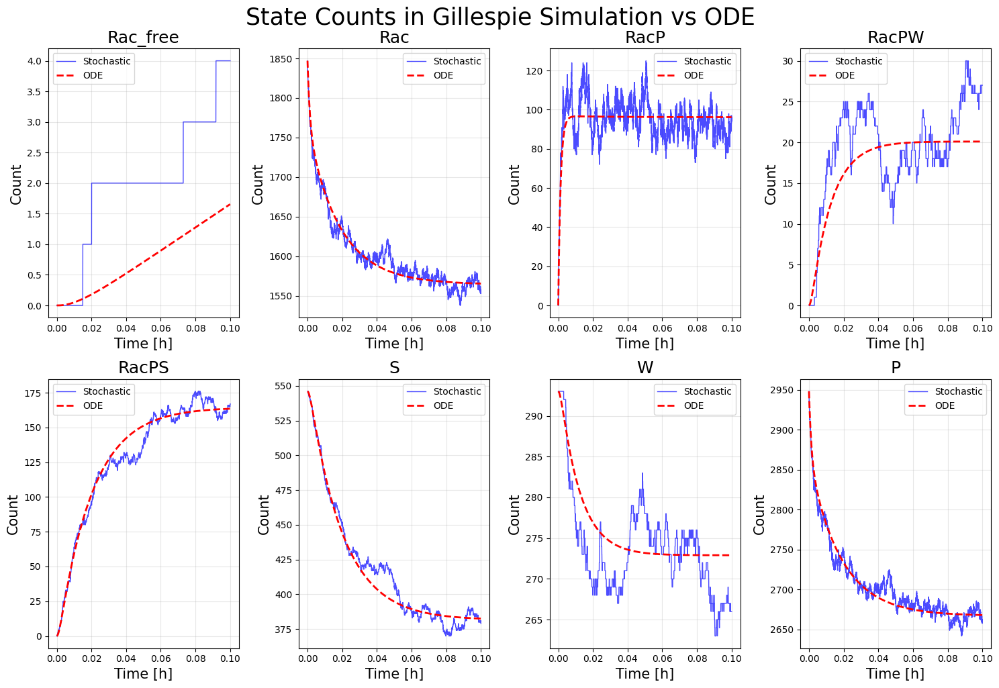

In [51]:
# Plot results
species_names = ['Rac_free', 'Rac', 'RacP', 'RacPW', 'RacPS', 'S', 'W', 'P']

plt.figure(figsize=(15, 10))
for i, name in enumerate(species_names):
    plt.subplot(2, 4, i+1)
    # Plot stochastic trajectory
    plt.plot(times/3600, states[:, i], 'b-', alpha=0.7, linewidth=1, label='Stochastic')
    # Plot deterministic trajectory
    plt.plot(t_ode/3600, states_ode[:, i], 'r--', linewidth=2, label='ODE')
    # plt.plot(t_ode/3600, states_ode_original[:, i]/100, 'g--', linewidth=3, label='ODE Original')
    plt.xlabel('Time [h]', fontsize=15)
    plt.ylabel('Count', fontsize=15)
    plt.title(f'{name}', fontsize=18)
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.suptitle('State Counts in Gillespie Simulation vs ODE', fontsize=25, y=1.02)
plt.show()
# Conservation check
initial_total = np.sum(initial)
final_total = np.sum(states[-1])
ode_final_total = np.sum(states_ode[-1]) 

### Tracking the proportion of states over time

In [406]:
def track_molecules_until_falloff(reaction, old_state, new_state, time, tracked_molecules):
    """Track state changes for individual molecules until falling off"""
    
    # Get active tracked molecules in each state: Rac, RacP; RacPS; RacPW
    molecules_in_rac = [mol for mol in tracked_molecules.values() 
                       if mol['current_state'] == 'Rac' and mol['status'] == 'active']
    molecules_in_racp = [mol for mol in tracked_molecules.values() 
                        if mol['current_state'] == 'RacP' and mol['status'] == 'active']
    molecules_in_racps = [mol for mol in tracked_molecules.values() 
                         if mol['current_state'] == 'RacPS' and mol['status'] == 'active']
    molecules_in_racpw = [mol for mol in tracked_molecules.values() 
                         if mol['current_state'] == 'RacPW' and mol['status'] == 'active']
    
    new_falloffs = 0
    
    # Helper functions for P state tracking
    def start_p_state_tracking(mol, time):
        if mol['current_p_state_start'] is None:
            mol['current_p_state_start'] = time
    
    def end_p_state_tracking(mol, time):
        if mol['current_p_state_start'] is not None:
            duration = time - mol['current_p_state_start']
            mol['p_state_durations'].append(duration)
            mol['p_state_visits'] += 1
            mol['current_p_state_start'] = None
    
    # [Rac_free, Rac, RacP, RacPW, RacPS, S, W, P]
    
    if reaction == 0:  # R1: Rac + P -> RacP
        # Calculate what fraction of total Rac molecules transitioned
        total_rac = old_state[1]  # Total Rac molecules in system
        molecules_transitioned = new_state[2] - old_state[2]  # How many transitioned
        
        if total_rac > 0 and molecules_transitioned  > 0:
            # Probability that any given Rac molecule transitions
            transition_prob = molecules_transitioned  / total_rac

            for mol in molecules_in_rac:
                if np.random.random() < transition_prob:
                    # Complete Rac visit and record duration
                    if mol['current_visit_start']['Rac'] is not None:
                        duration = time - mol['current_visit_start']['Rac']
                        mol['visit_durations']['Rac'].append(duration)
                        mol['visits_before_falloff']['Rac'] += 1
                        mol['current_visit_start']['Rac'] = None

                    # Rac -> RacP, at time append RacP
                    mol['current_state'] = 'RacP'
                    mol['state_history'].append(('RacP', time))
                    mol['current_visit_start']['RacP'] = time
                    start_p_state_tracking(mol, time)

    elif reaction == 1:  # R2: RacP -> Rac + P
        total_racp = old_state[2]  # Total RacP molecules
        molecules_transitioned = old_state[2] - new_state[2]  # How many transitioned
       
        if total_racp > 0 and molecules_transitioned > 0:
            transition_prob = molecules_transitioned / total_racp
            
            for mol in molecules_in_racp:
                if np.random.random() < transition_prob:
                    # Complete RacP visit and record duration
                    if mol['current_visit_start']['RacP'] is not None:
                        duration = time - mol['current_visit_start']['RacP']
                        mol['visit_durations']['RacP'].append(duration)
                        mol['visits_before_falloff']['RacP'] += 1
                        mol['current_visit_start']['RacP'] = None
                    # RacP -> Rac
                    end_p_state_tracking(mol, time)
                    mol['current_state'] = 'Rac'
                    mol['state_history'].append(('Rac', time))
                    mol['current_visit_start']['Rac'] = time
    
    elif reaction == 2:  # R3: RacP + S -> RacPS
        total_racp = old_state[2]
        molecules_transitioned = old_state[2] - new_state[2]
        
        if total_racp > 0 and molecules_transitioned > 0:
            transition_prob = molecules_transitioned / total_racp
            
            for mol in molecules_in_racp:
                if np.random.random() < transition_prob:
                    # Complete RacP visit and record duration
                    if mol['current_visit_start']['RacP'] is not None:
                        duration = time - mol['current_visit_start']['RacP']
                        mol['visit_durations']['RacP'].append(duration)
                        mol['visits_before_falloff']['RacP'] += 1
                        mol['current_visit_start']['RacP'] = None
                    # RacP -> RacPS
                    mol['current_state'] = 'RacPS'
                    mol['state_history'].append(('RacPS', time))
                    mol['current_visit_start']['RacPS'] = time
    
    elif reaction == 3:  # R4: RacPS -> RacP + S
        total_racps = old_state[4]
        molecules_transitioned = old_state[4] - new_state[4]
        
        if total_racps > 0 and molecules_transitioned > 0:
            transition_prob = molecules_transitioned / total_racps

            for mol in molecules_in_racps:
                if np.random.random() < transition_prob:
                    # Complete RacPS visit and record duration 
                    if mol['current_visit_start']['RacPS'] is not None:
                        duration = time - mol['current_visit_start']['RacPS']
                        mol['visit_durations']['RacPS'].append(duration)
                        mol['visits_before_falloff']['RacPS'] += 1
                        mol['current_visit_start']['RacPS'] = None
                    # RacPS -> RacP
                    mol['current_state'] = 'RacP'
                    mol['state_history'].append(('RacP', time))
                    mol['current_visit_start']['RacP'] = time

    elif reaction == 4:  # R5: RacP + W -> RacPW
        total_racp = old_state[2]
        molecules_transitioned = old_state[2] - new_state[2]
       
        if total_racp > 0 and molecules_transitioned > 0:
            transition_prob = molecules_transitioned / total_racp
            
            for mol in molecules_in_racp:
                if np.random.random() < transition_prob:
                    # Complete RacP visit and record duration
                    if mol['current_visit_start']['RacP'] is not None:
                        duration = time - mol['current_visit_start']['RacP']
                        mol['visit_durations']['RacP'].append(duration)
                        mol['visits_before_falloff']['RacP'] += 1
                        mol['current_visit_start']['RacP'] = None
                    # RacP -> RacPW
                    mol['current_state'] = 'RacPW'
                    mol['state_history'].append(('RacPW', time))
                    mol['current_visit_start']['RacPW'] = time
    
    elif reaction == 5:  # R6: RacPW -> RacP + W
        
        total_racpw = old_state[3]
        molecules_transitioned = old_state[3] - new_state[3]
        
        if total_racpw > 0 and molecules_transitioned > 0:
            transition_prob = molecules_transitioned / total_racpw
            
            for mol in molecules_in_racpw:
                if np.random.random() < transition_prob:
                    # Complete RacPW visit and record duration
                    if mol['current_visit_start']['RacPW'] is not None:
                        duration = time - mol['current_visit_start']['RacPW']
                        mol['visit_durations']['RacPW'].append(duration)
                        mol['visits_before_falloff']['RacPW'] += 1
                        mol['current_visit_start']['RacPW'] = None 
                    # RacPW -> RacP
                    mol['current_state'] = 'RacP'
                    mol['state_history'].append(('RacP', time))
                    mol['current_visit_start']['RacP'] = time
    
    elif reaction == 6:  # R7: RacPW -> Rac_free + P + W (FALLOFF!)
        total_racpw = old_state[3]
        molecules_transitioned = old_state[3] - new_state[3]
        
        if total_racpw > 0 and molecules_transitioned > 0:
            transition_prob = molecules_transitioned / total_racpw
            
            for mol in molecules_in_racpw:
                if np.random.random() < transition_prob:
                    # Complete RacPW visit and record duration
                    if mol['current_visit_start']['RacPW'] is not None:
                        duration = time - mol['current_visit_start']['RacPW']
                        mol['visit_durations']['RacPW'].append(duration)
                        mol['visits_before_falloff']['RacPW'] += 1
                        mol['current_visit_start']['RacPW'] = None
                    # RacPW -> Rac_free (FIRST FALLOFF! end P-state tracking due to fall off) 
                    end_p_state_tracking(mol, time)
                    
                    mol['current_state'] = 'Rac_free'
                    mol['state_history'].append(('Rac_free', time))
                    mol['status'] = 'fell_off'
                    mol['falloff_time'] = time
                    mol['has_fallen_off'] = True
                    new_falloffs += 1
    
    return new_falloffs

In [409]:
def analyze_falloff_statistics(tracked_molecules, pickup_time, end_time):
    """Analyze statistics for molecules that fell off"""
    print(f"\n FALLOFF ANALYSIS")
    print("=" * 80)
    
    fallen_off_molecules = [mol for mol in tracked_molecules.values() if mol['has_fallen_off']]
    still_active = [mol for mol in tracked_molecules.values() if mol['status'] == 'still_active']
    
    total_molecules = len(tracked_molecules)
    falloff_count = len(fallen_off_molecules)
    
    print(f"Total molecules tracked: {total_molecules}")
    print(f"Fell off (reached Rac_free): {falloff_count} ({falloff_count/total_molecules*100:.1f}%)")
    print(f"Still active at end time: {len(still_active)} ({len(still_active)/total_molecules*100:.1f}%)")
    
    if not fallen_off_molecules:
        print("\nNo molecules fell off yet - might need longer simulation time!")
        return
    
    # Calculate visit statistics for fallen off molecules ONLY
    rac_visits_before_falloff = [mol['visits_before_falloff']['Rac'] for mol in fallen_off_molecules]
    racps_visits_before_falloff = [mol['visits_before_falloff']['RacPS'] for mol in fallen_off_molecules]
    racp_visits_before_falloff = [mol['visits_before_falloff']['RacP'] for mol in fallen_off_molecules]
    racpw_visits_before_falloff = [mol['visits_before_falloff']['RacPW'] for mol in fallen_off_molecules]

    mean_rac_visits = np.mean(rac_visits_before_falloff)
    mean_racps_visits = np.mean(racps_visits_before_falloff)
    std_racps_visits = np.std(racps_visits_before_falloff)
    mean_racp_visits = np.mean(racp_visits_before_falloff)
    mean_racpw_visits = np.mean(racpw_visits_before_falloff)
    
    # P related state visit statistics
    p_visits_before_falloff = [mol['p_state_visits'] for mol in fallen_off_molecules]
    mean_p_visits = np.mean(p_visits_before_falloff)
    std_p_visits = np.std(p_visits_before_falloff)
    
    # Calculate falloff times
    falloff_times = [(mol['falloff_time'] - mol['pickup_time']) for mol in fallen_off_molecules]
    mean_falloff_time = np.mean(falloff_times)
    
    print(f"\nRESULT - MEAN VISITS BEFORE FIRST FALLOFF:")
    print(f"Mean Rac visits:  {mean_rac_visits:.3f}")
    print(f"Mean RacPS visits: {mean_racps_visits:.3f} ± {std_racps_visits:.3f}")
    print(f"Mean RacP visits:  {mean_racp_visits:.3f}")
    print(f"Mean RacPW visits: {mean_racpw_visits:.3f}")
    print(f"Mean P-state visits: {mean_p_visits:.3f} ± {std_p_visits:.3f}")
    print(f"Range RacPS: {min(racps_visits_before_falloff)} - {max(racps_visits_before_falloff)} visits")
    print(f"Range P-state: {min(p_visits_before_falloff)} - {max(p_visits_before_falloff)} visits")
    
    # Calculate visit duration statistics
    print(f"\nMEAN TIME SPENT PER VISIT (only fallen off molecules):")
    print("=" * 80)
    
    for state_name in ['Rac', 'RacP', 'RacPS', 'RacPW']:
        # Collect all visit durations for this state from all fallen off molecules
        all_durations = []
        for mol in fallen_off_molecules:
            all_durations.extend(mol['visit_durations'][state_name])
        
        if all_durations:
            mean_duration = np.mean(all_durations)
            std_duration = np.std(all_durations)
            median_duration = np.median(all_durations)
            total_visits = len(all_durations)
            
            print(f"{state_name:6s}: {mean_duration:.6f}s ± {std_duration:.6f}s "
                  f"(median: {median_duration:.6f}s, n={total_visits} visits)")
        else:
            print(f"{state_name:6s}: No visits recorded")
    
    # P-state duration statistics
    print(f"\nP-STATE DURATION ANALYSIS:")
    print("=" * 80)
    
    all_p_durations = []
    for mol in fallen_off_molecules:
        all_p_durations.extend(mol['p_state_durations'])
    
    if all_p_durations:
        mean_p_duration = np.mean(all_p_durations)
        std_p_duration = np.std(all_p_durations)
        median_p_duration = np.median(all_p_durations)
        total_p_visits = len(all_p_durations)
        
        print(f"P-state: {mean_p_duration:.6f}s ± {std_p_duration:.6f}s "
              f"(median: {median_p_duration:.6f}s, n={total_p_visits} periods)")
        print(f"Min P-state duration: {min(all_p_durations):.6f}s")
        print(f"Max P-state duration: {max(all_p_durations):.6f}s")
    else:
        print("P-state: No P-state periods recorded")

    # Calculate average visit durations per-molecule
    print(f"\nPER-MOLECULE AVERAGE VISIT DURATIONS:")
    print("=" * 80)
    
    for state_name in ['Rac', 'RacP', 'RacPS', 'RacPW']:
        molecule_avg_durations = []
        for mol in fallen_off_molecules:
            if mol['visit_durations'][state_name]:
                avg_duration = np.mean(mol['visit_durations'][state_name])
                molecule_avg_durations.append(avg_duration)
        
        if molecule_avg_durations:
            mean_of_averages = np.mean(molecule_avg_durations)
            std_of_averages = np.std(molecule_avg_durations)
            print(f"{state_name:6s}: {mean_of_averages:.6f}s ± {std_of_averages:.6f}s"
                  f"(n={len(molecule_avg_durations)} molecules)")
        else:
            print(f"{state_name:6s}: No molecules with visits")
    
    # Per-molecule average P-state durations
    molecule_avg_p_durations = []
    for mol in fallen_off_molecules:
        if mol['p_state_durations']:
            avg_p_duration = np.mean(mol['p_state_durations'])
            molecule_avg_p_durations.append(avg_p_duration)
    
    if molecule_avg_p_durations:
        mean_of_p_averages = np.mean(molecule_avg_p_durations)
        std_of_p_averages = np.std(molecule_avg_p_durations)
        print(f"P-state: {mean_of_p_averages:.6f}s ± {std_of_p_averages:.6f}s "
              f"(n={len(molecule_avg_p_durations)} molecules)")
        
    print(f"\nMean time to falloff: {mean_falloff_time:.3f}s")
    
    # Detailed breakdown
    print(f"\nDETAILED BREAKDOWN (first 20 fallen off molecules):")
    print("Mol ID | Rac| RacP | RacPS | RacPW | Avg Rac| Avg RacP | Avg RacPS | Avg RacPW | Falloff Time")
    print("-" * 90)
    
    for i, mol in enumerate(fallen_off_molecules[:20]):
        rac_visits = mol['visits_before_falloff']['Rac']
        racp_visits = mol['visits_before_falloff']['RacP']
        racps_visits = mol['visits_before_falloff']['RacPS']
        racpw_visits = mol['visits_before_falloff']['RacPW']
        p_visits = mol['p_state_visits']
        
        # Calculate average durations for this molecule
        avg_rac = np.mean(mol['visit_durations']['Rac']) if mol['visit_durations']['Rac'] else 0
        avg_racp = np.mean(mol['visit_durations']['RacP']) if mol['visit_durations']['RacP'] else 0
        avg_racps = np.mean(mol['visit_durations']['RacPS']) if mol['visit_durations']['RacPS'] else 0
        avg_racpw = np.mean(mol['visit_durations']['RacPW']) if mol['visit_durations']['RacPW'] else 0
        avg_p = np.mean(mol['p_state_durations']) if mol['p_state_durations'] else 0
        
        falloff_duration = mol['falloff_time'] - mol['pickup_time']
        
        print(f"{mol['id']:6d} | {rac_visits:4d} | {racp_visits:4d} | {racps_visits:5d} | {racpw_visits:5d} | {p_visits:8d} | "
              f"{avg_rac:8.4f} | {avg_racp:8.4f} | {avg_racps:9.4f} | {avg_racpw:9.4f} | {avg_p:11.4f} | {falloff_duration:11.3f}s")
    
    if len(fallen_off_molecules) > 20:
        print(f"... and {len(fallen_off_molecules) - 20} more molecules")
    
    # Show distribution
    print(f"\nRacPS VISIT DISTRIBUTION:")
    unique_visits, counts = np.unique(racps_visits_before_falloff, return_counts=True)
    for visits, count in zip(unique_visits, counts):
        percentage = count / len(fallen_off_molecules) * 100
        print(f"  {visits:2d} visits: {count:3d} molecules ({percentage:.1f}%)")
    
    # P-state visit distribution
    print(f"\nP-STATE VISIT DISTRIBUTION:")
    unique_p_visits, p_counts = np.unique(p_visits_before_falloff, return_counts=True)
    for visits, count in zip(unique_p_visits, p_counts):
        percentage = count / len(fallen_off_molecules) * 100
        print(f"  {visits:2d} P-periods: {count:3d} molecules ({percentage:.1f}%)")

In [411]:
def track_rac_until_first_falloff_with_snapshots(rates, stoich_matrix, initial_state, 
                pickup_time = 1000, max_time = 1e6, dt = 100):
    """
    Track Rac molecules from pickup_time until first falloff,
    save snapshots as total counts of each species including free S, P, W,
    and keep the original tracked_molecules dict.
    """
    # Initialize state
    state = np.array(initial_state, dtype=int)
    time = 0

    # Run simulation until pickup_time
    while time < pickup_time:
        props = calculate_propensities(state, rates)
        prop_sum = np.sum(props)
        if prop_sum == 0: 
            break
        tau = np.random.exponential(1.0 / prop_sum)
        time += tau
        reaction = np.random.choice(len(props), p=props/prop_sum)
        new_state = state + stoich_matrix[reaction]
        if np.any(new_state < 0): 
            continue
        state = new_state

    # Pick up Rac molecules at pickup_time
    num_rac_molecules = state[1]
    print(f"\n PICKUP at t={time:.3f}s | {num_rac_molecules} Rac molecules")
    
    if num_rac_molecules == 0:
        print("No Rac molecules to track!")
        return {}, [], []

    tracked_molecules = {}
    for i in range(num_rac_molecules):
        tracked_molecules[i] = {
            'id': i,
            'current_state': 'Rac',
            'pickup_time': time,
            'visits_before_falloff': {'Rac': 0, 'RacP': 0, 'RacPS': 0, 'RacPW': 0},
            # Start tracking Rac immediately
            'current_visit_start': {'Rac': time, 'RacP': None, 'RacPS': None, 'RacPW': None},  
            # Track all visit durations for each state
            'visit_durations': {'Rac': [], 'RacP': [], 'RacPS': [], 'RacPW': []},
            # P related state tracking fields, 
            'current_p_state_start': None,  # When the current P-state period started
            'p_state_durations': [],        # List of all P-state durations
            'p_state_visits': 0,            # Number of separate P-state periods
            'state_history': [('Rac', time)],
            'status': 'active',  # 'active', 'fell_off', 'still_active'
            'falloff_time': None,
            'has_fallen_off': False
        }

    # Prepare snapshots which store total counts for each species
    snapshots = []     
    time_points = []
    next_snapshot_time = time + dt
    step_count = 0
    molecules_fallen_off = 0

    # Main simulation loop
    while time < max_time:
        props = calculate_propensities(state, rates)
        prop_sum = np.sum(props)
        if prop_sum == 0: 
            break
        tau = np.random.exponential(1.0 / prop_sum)
        time += tau
        reaction = np.random.choice(len(props), p=props/prop_sum)
        new_state = state + stoich_matrix[reaction]
        if np.any(new_state < 0): 
            continue

        # Track molecular transitions until first falloff
        new_falloffs = track_molecules_until_falloff(reaction, state, new_state, time, tracked_molecules)
        molecules_fallen_off += new_falloffs
        state = new_state
        step_count += 1

        # Save snapshots, only saving total counts for each species
        if time >= next_snapshot_time:
            species_counts = {
                'Rac_free': state[0],
                'Rac': state[1],
                'RacP': state[2],
                'RacPW': state[3],
                'RacPS': state[4],
                'S': state[5],
                'W': state[6],
                'P': state[7]
            }
            snapshots.append(species_counts)
            time_points.append(time)
            next_snapshot_time += dt

        # Progress update
        if step_count % 50000 == 0:
            active_count = sum(1 for mol in tracked_molecules.values() if mol['status'] == 'active')
            print(f"t={time:.1f}s | Active: {active_count} | Fallen off: {molecules_fallen_off}")

    # Final snapshot at the end
    species_counts = {
                'Rac_free': state[0],
                'Rac': state[1],
                'RacP': state[2],
                'RacPW': state[3],
                'RacPS': state[4],
                'S': state[5],
                'W': state[6],
                'P': state[7]
            }
    snapshots.append(species_counts)
    time_points.append(time)

    # Finalize molecules still active
    for mol in tracked_molecules.values():
        if mol['status'] == 'active':
            mol['status'] = 'still_active'

    print(f"\n TRACKING COMPLETED at t={time:.3f}s")
    
    # Optional, after tracking can analysis and output the falloff statistic 
    analyze_falloff_statistics(tracked_molecules, pickup_time, time)
    
    # Return the original dictionary, time points, and simplified snapshots
    return list(tracked_molecules.values()), time_points, snapshots

In [412]:
def create_falloff_analysis_plots(tracked_molecules):
    """Create plots for falloff analysis including visit durations"""
    fallen_off_molecules = [mol for mol in tracked_molecules if mol['has_fallen_off']]
    
    if not fallen_off_molecules:
        print("No fallen off molecules to plot!")
        return
    
    rac_visits = [mol['visits_before_falloff']['Rac'] for mol in fallen_off_molecules]
    racps_visits = [mol['visits_before_falloff']['RacPS'] for mol in fallen_off_molecules]
    racp_visits = [mol['visits_before_falloff']['RacP'] for mol in fallen_off_molecules]
    racpw_visits = [mol['visits_before_falloff']['RacPW'] for mol in fallen_off_molecules]
    falloff_times = [(mol['falloff_time'] - mol['pickup_time']) for mol in fallen_off_molecules]
    
    # Collect P-state data
    p_visits = [mol['p_state_visits'] for mol in fallen_off_molecules]
    all_p_durations = []
    for mol in fallen_off_molecules:
        all_p_durations.extend(mol['p_state_durations'])

    # Collect all visit durations
    all_rac_durations = []
    all_racp_durations = []
    all_racps_durations = []
    all_racpw_durations = []
    
    for mol in fallen_off_molecules:
        all_rac_durations.extend(mol['visit_durations']['Rac'])
        all_racp_durations.extend(mol['visit_durations']['RacP'])
        all_racps_durations.extend(mol['visit_durations']['RacPS'])
        all_racpw_durations.extend(mol['visit_durations']['RacPW'])
    
    fig, axes = plt.subplots(3, 5, figsize=(15, 12))

    # First row: visit count histograms
    axes[0,0].hist(rac_visits, bins=range(max(rac_visits)+2), alpha=0.7, color='red', edgecolor='black')
    axes[0,0].set_title(f'Rac Visits Before Falloff\n(Mean: {np.mean(rac_visits):.2f})', fontsize=16)
    axes[0,0].set_xlabel('Number of Rac visits', fontsize=14)
    axes[0,0].set_ylabel('Number of molecules', fontsize=14)
    axes[0,0].axvline(np.mean(rac_visits), color='black', linestyle='--', label=f'Mean: {np.mean(rac_visits):.2f}')
    axes[0,0].legend()

    axes[0,1].hist(racps_visits, bins=range(max(racps_visits)+2), alpha=0.7, color='green', edgecolor='black')
    axes[0,1].set_title(f'RacPS Visits Before Falloff\n(Mean: {np.mean(racps_visits):.2f})', fontsize=16)
    axes[0,1].set_xlabel('Number of RacPS visits', fontsize=14)
    axes[0,1].set_ylabel('Number of molecules', fontsize=14)
    axes[0,1].axvline(np.mean(racps_visits), color='black', linestyle='--', label=f'Mean: {np.mean(racps_visits):.2f}')
    axes[0,1].legend()

    axes[0,2].hist(racp_visits, bins=range(max(racp_visits)+2), alpha=0.7, color='blue', edgecolor='black')
    axes[0,2].set_title(f'RacP Visits Before Falloff\n(Mean: {np.mean(racp_visits):.2f})', fontsize=16)
    axes[0,2].set_xlabel('Number of RacP visits', fontsize=14)
    axes[0,2].set_ylabel('Number of molecules', fontsize=14)
    axes[0,2].axvline(np.mean(racp_visits), color='black', linestyle='--', label=f'Mean: {np.mean(racp_visits):.2f}')
    axes[0,2].legend()
    
    axes[0,3].hist(racpw_visits, bins=range(max(racpw_visits)+2), alpha=0.7, color='purple', edgecolor='black')
    axes[0,3].set_title(f'RacPW Visits Before Falloff\n(Mean: {np.mean(racpw_visits):.2f})', fontsize=16)
    axes[0,3].set_xlabel('Number of RacPW visits', fontsize=14)
    axes[0,3].set_ylabel('Number of molecules', fontsize=14)
    axes[0,3].axvline(np.mean(racpw_visits), color='black', linestyle='--', label=f'Mean: {np.mean(racpw_visits):.2f}')
    axes[0,3].legend()
    
    # P-state visits histogram
    if p_visits:
        axes[0,4].hist(p_visits, bins=range(max(p_visits)+2), alpha=0.7, color='orange', edgecolor='black')
        axes[0,4].set_title(f'P-State Visits Before Falloff\n(Mean: {np.mean(p_visits):.2f})', fontsize=16)
        axes[0,4].set_xlabel('Number of P-state visits', fontsize=14)
        axes[0,4].set_ylabel('Number of molecules', fontsize=14)
        axes[0,4].axvline(np.mean(p_visits), color='black', linestyle='--', label=f'Mean: {np.mean(p_visits):.2f}')
        axes[0,4].legend()
    
    # Second row: Visit duration histograms
    if all_rac_durations:
        axes[1,0].hist(all_rac_durations, bins=50, alpha=0.7, color='red', edgecolor='black')
        axes[1,0].set_title(f'Rac Visit Durations\n(Mean: {np.mean(all_rac_durations):.4f}s)', fontsize=16)
        axes[1,0].set_xlabel('Visit duration (s)', fontsize=14)
        axes[1,0].set_ylabel('Number of visits', fontsize=14)
        axes[1,0].axvline(np.mean(all_rac_durations), color='black', linestyle='--')
    
    if all_racps_durations:
        axes[1,1].hist(all_racps_durations, bins=50, alpha=0.7, color='green', edgecolor='black')
        axes[1,1].set_title(f'RacPS Visit Durations\n(Mean: {np.mean(all_racps_durations):.4f}s)', fontsize=16)
        axes[1,1].set_xlabel('Visit duration (s)', fontsize=14)
        axes[1,1].set_ylabel('Number of visits', fontsize=14)
        axes[1,1].axvline(np.mean(all_racps_durations), color='black', linestyle='--')
    
    if all_racp_durations:
        axes[1,2].hist(all_racp_durations, bins=50, alpha=0.7, color='blue', edgecolor='black')
        axes[1,2].set_title(f'RacP Visit Durations\n(Mean: {np.mean(all_racp_durations):.4f}s)', fontsize=16)
        axes[1,2].set_xlabel('Visit duration (s)', fontsize=14)
        axes[1,2].set_ylabel('Number of visits', fontsize=14)
        axes[1,2].axvline(np.mean(all_racp_durations), color='black', linestyle='--')
    
    if all_racpw_durations:
        axes[1,3].hist(all_racpw_durations, bins=50, alpha=0.7, color='purple', edgecolor='black')
        axes[1,3].set_title(f'RacPW Visit Durations\n(Mean: {np.mean(all_racpw_durations):.4f}s)', fontsize=16)
        axes[1,3].set_xlabel('Visit duration (s)', fontsize=14)
        axes[1,3].set_ylabel('Number of visits', fontsize=14)
        axes[1,3].axvline(np.mean(all_racpw_durations), color='black', linestyle='--')
    
    # P-state duration histogram
    if all_p_durations:
        axes[1,4].hist(all_p_durations, bins=50, alpha=0.7, color='orange', edgecolor='black')
        axes[1,4].set_title(f'P-State Durations\n(Mean: {np.mean(all_p_durations):.4f}s)', fontsize=16)
        axes[1,4].set_xlabel('P-state duration (s)', fontsize=14)
        axes[1,4].set_ylabel('Number of periods', fontsize=14)
        axes[1,4].axvline(np.mean(all_p_durations), color='black', linestyle='--')

    # Third row: Analysis plots
    axes[2,0].hist(falloff_times, bins=20, alpha=0.7, color='orange', edgecolor='black')
    axes[2,0].set_title(f'Time to Falloff\n(Mean: {np.mean(falloff_times):.1f}s)', fontsize=16)
    axes[2,0].set_xlabel('Time to falloff (s)', fontsize=14)
    axes[2,0].set_ylabel('Number of molecules', fontsize=14)
    
    # RacPS visits vs falloff time
    axes[2,1].scatter(racps_visits, falloff_times, alpha=0.6)
    axes[2,1].set_title('RacPS Visits vs Falloff Time', fontsize=16)
    axes[2,1].set_xlabel('RacPS visits before falloff', fontsize=14)
    axes[2,1].set_ylabel('Time to falloff (s)', fontsize=14)
    
    # P-state visits vs falloff time
    if p_visits:
        axes[2,2].scatter(p_visits, falloff_times, alpha=0.6, color='orange')
        axes[2,2].set_title('P state visits vs Falloff Time', fontsize=14)
        axes[2,2].set_xlabel('P state visits before falloff', fontsize=12)
        axes[2,2].set_ylabel('Time to falloff (s)', fontsize=12)
    
    # Average RacPS duration per molecule
    mol_avg_racps_durations = []
    for mol in fallen_off_molecules:
        if mol['visit_durations']['RacPS']:
            mol_avg_racps_durations.append(np.mean(mol['visit_durations']['RacPS']))
    
    if mol_avg_racps_durations:
        axes[2,3].hist(mol_avg_racps_durations, bins=20, alpha=0.7, color='green', edgecolor='black')
        axes[2,3].set_title(f'Per-Molecule Avg RacPS Duration\n(Mean: {np.mean(mol_avg_racps_durations):.4f}s)', fontsize=14)
        axes[2,3].set_xlabel('Average RacPS duration per molecule (s)', fontsize=12)
        axes[2,3].set_ylabel('Number of molecules', fontsize=12)
    
    mol_avg_racpw_durations = []
    for mol in fallen_off_molecules:
        if mol['visit_durations']['RacPW']:
            mol_avg_racpw_durations.append(np.mean(mol['visit_durations']['RacPW']))

    if mol_avg_racpw_durations:
        axes[2,4].hist(mol_avg_racpw_durations, bins=20, alpha=0.7, color='green', edgecolor='black')
        axes[2,4].set_title(f'Per-Molecule Avg RacPW Duration\n(Mean: {np.mean(mol_avg_racpw_durations):.4f}s)', fontsize=14)
        axes[2,4].set_xlabel('Average RacPW duration per molecule (s)', fontsize=12)
        axes[2,4].set_ylabel('Number of molecules', fontsize=12)
    
    plt.tight_layout()
    plt.suptitle(f'Falloff molecules Analysis ({len(fallen_off_molecules)} molecules)', fontsize=18, y=1.02)
    plt.show()

In [420]:
def create_unfallen_analysis_plots(tracked_molecules, current_time):
    """Create plots for molecules that haven't fallen off yet (still active)"""
    unfallen_molecules = [mol for mol in tracked_molecules if mol['status'] == 'still_active']
    
    if not unfallen_molecules:
        print("No unfallen molecules to plot!")
        return
    
    print(f"Analyzing {len(unfallen_molecules)} unfallen molecules at t={current_time:.1f}s")
    
    # Extract visit counts for unfalloff molecules 
    rac_visits = [mol['visits_before_falloff']['Rac'] for mol in unfallen_molecules]
    racps_visits = [mol['visits_before_falloff']['RacPS'] for mol in unfallen_molecules]
    racp_visits = [mol['visits_before_falloff']['RacP'] for mol in unfallen_molecules]
    racpw_visits = [mol['visits_before_falloff']['RacPW'] for mol in unfallen_molecules]
    
    # P-state data for unfallen molecules
    p_visits = [mol['p_state_visits'] for mol in unfallen_molecules]
    all_p_durations = []
    for mol in unfallen_molecules:
        all_p_durations.extend(mol['p_state_durations'])

    # Calculate survival times (time since pickup)
    survival_times = [(current_time - mol['pickup_time']) for mol in unfallen_molecules]
    
    # Current state distribution
    current_states = [mol['current_state'] for mol in unfallen_molecules]
    state_counts = {}
    for state in ['Rac', 'RacP', 'RacPS', 'RacPW']:
        state_counts[state] = current_states.count(state)
    
    # Collect all visit durations (completed visits only)
    all_rac_durations = []
    all_racp_durations = []
    all_racps_durations = []
    all_racpw_durations = []
    
    for mol in unfallen_molecules:
        all_rac_durations.extend(mol['visit_durations']['Rac'])
        all_racp_durations.extend(mol['visit_durations']['RacP'])
        all_racps_durations.extend(mol['visit_durations']['RacPS'])
        all_racpw_durations.extend(mol['visit_durations']['RacPW'])
    
    fig, axes = plt.subplots(3, 5, figsize=(16, 12))

    # First row: Visit count histograms for unfallen molecules
    if rac_visits:
        axes[0,0].hist(rac_visits, bins=range(max(rac_visits)+2), alpha=0.7, color='lightcoral', edgecolor='black')
        axes[0,0].set_title(f'Rac Visits (Unfallen)\n(Mean: {np.mean(rac_visits):.2f})', fontsize=16)
        axes[0,0].set_xlabel('Number of Rac visits', fontsize=14)
        axes[0,0].set_ylabel('Number of molecules', fontsize=14)
        axes[0,0].axvline(np.mean(rac_visits), color='black', linestyle='--')

    if racps_visits:
        axes[0,1].hist(racps_visits, bins=range(max(racps_visits)+2), alpha=0.7, color='lightgreen', edgecolor='black')
        axes[0,1].set_title(f'RacPS Visits (Unfallen)\n(Mean: {np.mean(racps_visits):.2f})', fontsize=16)
        axes[0,1].set_xlabel('Number of RacPS visits', fontsize=14)
        axes[0,1].set_ylabel('Number of molecules', fontsize=14)
        axes[0,1].axvline(np.mean(racps_visits), color='black', linestyle='--')

    if racp_visits:
        axes[0,2].hist(racp_visits, bins=range(max(racp_visits)+2), alpha=0.7, color='lightblue', edgecolor='black')
        axes[0,2].set_title(f'RacP Visits (Unfallen)\n(Mean: {np.mean(racp_visits):.2f})', fontsize=16)
        axes[0,2].set_xlabel('Number of RacP visits', fontsize=14)
        axes[0,2].set_ylabel('Number of molecules', fontsize=14)
        axes[0,2].axvline(np.mean(racp_visits), color='black', linestyle='--')
    
    if racpw_visits:
        axes[0,3].hist(racpw_visits, bins=range(max(racpw_visits)+2), alpha=0.7, color='plum', edgecolor='black')
        axes[0,3].set_title(f'RacPW Visits (Unfallen)\n(Mean: {np.mean(racpw_visits):.2f})', fontsize=16)
        axes[0,3].set_xlabel('Number of RacPW visits', fontsize=14)
        axes[0,3].set_ylabel('Number of molecules', fontsize=14)
        axes[0,3].axvline(np.mean(racpw_visits), color='black', linestyle='--')
    
    # P-state visits histogram for unfallen
    if p_visits:
        axes[0,4].hist(p_visits, bins=range(max(p_visits)+2), alpha=0.7, color='lightsalmon', edgecolor='black')
        axes[0,4].set_title(f'P-State Periods (Unfallen)\n(Mean: {np.mean(p_visits):.2f})', fontsize=14)
        axes[0,4].set_xlabel('Number of P-state periods', fontsize=12)
        axes[0,4].set_ylabel('Number of molecules', fontsize=12)
        axes[0,4].axvline(np.mean(p_visits), color='black', linestyle='--')
    else:
        axes[0,4].text(0.5, 0.5, 'No completed\nP-state periods', ha='center', va='center', transform=axes[0,4].transAxes)
        axes[0,4].set_title('P-State Periods (Unfallen)', fontsize=14)
    
    # Second row: Visit duration histograms (completed visits only)
    if all_rac_durations:
        axes[1,0].hist(all_rac_durations, bins=30, alpha=0.7, color='lightcoral', edgecolor='black')
        axes[1,0].set_title(f'Rac Visit Durations (Unfallen)\n(Mean: {np.mean(all_rac_durations):.4f}s)', fontsize=16)
        axes[1,0].set_xlabel('Visit duration (s)', fontsize=14)
        axes[1,0].set_ylabel('Number of visits', fontsize=14)
        axes[1,0].axvline(np.mean(all_rac_durations), color='black', linestyle='--')
    else:
        axes[1,0].text(0.5, 0.5, 'No completed\nRac visits', ha='center', va='center', transform=axes[1,0].transAxes)
        axes[1,0].set_title('Rac Visit Durations (Unfallen)', fontsize=16)
    
    if all_racps_durations:
        axes[1,1].hist(all_racps_durations, bins=30, alpha=0.7, color='lightgreen', edgecolor='black')
        axes[1,1].set_title(f'RacPS Visit Durations (Unfallen)\n(Mean: {np.mean(all_racps_durations):.4f}s)', fontsize=16)
        axes[1,1].set_xlabel('Visit duration (s)', fontsize=14)
        axes[1,1].set_ylabel('Number of visits', fontsize=14)
        axes[1,1].axvline(np.mean(all_racps_durations), color='black', linestyle='--')
    else:
        axes[1,1].text(0.5, 0.5, 'No completed\nRacPS visits', ha='center', va='center', transform=axes[1,1].transAxes)
        axes[1,1].set_title('RacPS Visit Durations (Unfallen)')
    
    if all_racp_durations:
        axes[1,2].hist(all_racp_durations, bins=30, alpha=0.7, color='lightblue', edgecolor='black')
        axes[1,2].set_title(f'RacP Visit Durations (Unfallen)\n(Mean: {np.mean(all_racp_durations):.4f}s)', fontsize=16)
        axes[1,2].set_xlabel('Visit duration (s)', fontsize=14)
        axes[1,2].set_ylabel('Number of visits', fontsize=14)
        axes[1,2].axvline(np.mean(all_racp_durations), color='black', linestyle='--')
    else:
        axes[1,2].text(0.5, 0.5, 'No completed\nRacP visits', ha='center', va='center', transform=axes[1,2].transAxes)
        axes[1,2].set_title('RacP Visit Durations (Unfallen)', fontsize=16)

    if all_racpw_durations:
        axes[1,3].hist(all_racpw_durations, bins=30, alpha=0.7, color='plum', edgecolor='black')
        axes[1,3].set_title(f'RacPW Visit Durations (Unfallen)\n(Mean: {np.mean(all_racpw_durations):.4f}s)', fontsize=16)
        axes[1,3].set_xlabel('Visit duration (s)', fontsize=14)
        axes[1,3].set_ylabel('Number of visits', fontsize=14)
        axes[1,3].axvline(np.mean(all_racpw_durations), color='black', linestyle='--')
    else:
        axes[1,3].text(0.5, 0.5, 'No completed\nRacPW visits', ha='center', va='center', transform=axes[1,3].transAxes)
        axes[1,3].set_title('RacPW Visit Durations (Unfallen)', fontsize=16)
    
    # P-state duration histogram for unfallen
    if all_p_durations:
        axes[1,4].hist(all_p_durations, bins=30, alpha=0.7, color='lightsalmon', edgecolor='black')
        axes[1,4].set_title(f'P-State Period Durations (Unfallen)\n(Mean: {np.mean(all_p_durations):.4f}s)', fontsize=14)
        axes[1,4].set_xlabel('P-state period duration (s)', fontsize=12)
        axes[1,4].set_ylabel('Number of periods', fontsize=12)
        axes[1,4].axvline(np.mean(all_p_durations), color='black', linestyle='--')
    else:
        axes[1,4].text(0.5, 0.5, 'No completed\nP-state periods', ha='center', va='center', transform=axes[1,4].transAxes)
        axes[1,4].set_title('P-State Period Durations (Unfallen)', fontsize=14)
    
    # Third row: Analysis plots for unfallen molecules
    axes[2,0].hist(survival_times, bins=20, alpha=0.7, color='gold', edgecolor='black')
    axes[2,0].set_title(f'Survival Time (Unfallen)\n(Mean: {np.mean(survival_times):.1f}s)', fontsize=16)
    axes[2,0].set_xlabel('Time since pickup (s)', fontsize=14)
    axes[2,0].set_ylabel('Number of molecules', fontsize=14)
    axes[2,0].axvline(np.mean(survival_times), color='black', linestyle='--')
    
    # Current state distribution
    states = list(state_counts.keys())
    counts = list(state_counts.values())
    colors = ['lightcoral', 'lightblue', 'lightgreen', 'plum']
    
    axes[2,1].bar(states, counts, alpha=0.7, color=colors, edgecolor='black')
    axes[2,1].set_title('Current State Distribution (Unfallen)', fontsize=16)
    axes[2,1].set_xlabel('Current state', fontsize=14)
    axes[2,1].set_ylabel('Number of molecules', fontsize=14)
    
    # Add text labels on bars
    for i, (state, count) in enumerate(zip(states, counts)):
        if count > 0:
            axes[2,1].text(i, count + 0.1, str(count), ha='center', va='bottom')
    
    # RacPS visits vs survival time
    if racps_visits and survival_times:
        axes[2,2].scatter(racps_visits, survival_times, alpha=0.6, color='green')
        axes[2,2].set_title('RacPS Visits vs Survival Time', fontsize=16)
        axes[2,2].set_xlabel('RacPS visits so far', fontsize=14)
        axes[2,2].set_ylabel('Survival time (s)', fontsize=14)
    else:
        axes[2,2].text(0.5, 0.5, 'No RacPS visits\nto plot', ha='center', va='center', transform=axes[2,2].transAxes)
        axes[2,2].set_title('RacPS Visits vs Survival Time', fontsize=14)
    
    # P-state visits vs survival time
    if p_visits and survival_times:
        axes[2,3].scatter(p_visits, survival_times, alpha=0.6, color='orange')
        axes[2,3].set_title('P-State Periods vs Survival Time', fontsize=14)
        axes[2,3].set_xlabel('P-state periods so far', fontsize=12)
        axes[2,3].set_ylabel('Survival time (s)', fontsize=12)
    else:
        axes[2,3].text(0.5, 0.5, 'No P-state periods\nto plot', ha='center', va='center', transform=axes[2,3].transAxes)
        axes[2,3].set_title('P-State Periods vs Survival Time', fontsize=14)
    
    # Time in current state (for molecules currently in a state)
    current_state_durations = []
    current_state_labels = []
    
    for mol in unfallen_molecules:
        current_state = mol['current_state']
        if mol['current_visit_start'][current_state] is not None:
            duration = current_time - mol['current_visit_start'][current_state]
            current_state_durations.append(duration)
            current_state_labels.append(current_state)
    
    if current_state_durations:
        axes[2,4].hist(current_state_durations, bins=20, alpha=0.7, color='orange', edgecolor='black')
        axes[2,4].set_title(f'Time in Current State\n(Mean: {np.mean(current_state_durations):.2f}s)', fontsize=16)
        axes[2,4].set_xlabel('Duration in current state (s)', fontsize=14)
        axes[2,4].set_ylabel('Number of molecules', fontsize=14)
        axes[2,4].axvline(np.mean(current_state_durations), color='black', linestyle='--')
    else:
        axes[2,4].text(0.5, 0.5, 'No active\nstate durations', ha='center', va='center', transform=axes[2,3].transAxes)
        axes[2,4].set_title('Time in Current State', fontsize=16)
    
    plt.tight_layout()
    plt.suptitle(f'Unfallen Molecules Analysis ({len(unfallen_molecules)} molecules still active)', fontsize=18, y=1.02)
    plt.show()
    
    # Print summary statistics
    print(f"\n UNFALLEN MOLECULES SUMMARY:")
    print(f"Total unfallen molecules: {len(unfallen_molecules)}")
    print(f"Mean survival time: {np.mean(survival_times):.1f}s")
    print(f"Current state distribution:")
    for state, count in state_counts.items():
        if count > 0:
            print(f"  {state}: {count} molecules ({100*count/len(unfallen_molecules):.1f}%)")
    
    if racps_visits:
        print(f"Mean RacPS visits so far: {np.mean(racps_visits):.2f}")
    if all_racps_durations:
        print(f"Mean RacPS visit duration: {np.mean(all_racps_durations):.4f}s")
    
    # P-state summary for unfallen molecules
    if p_visits:
        print(f"Mean P-state periods so far: {np.mean(p_visits):.2f}")
        print(f"Max P-state periods: {max(p_visits)}")
    if all_p_durations:
        print(f"Mean P-state period duration: {np.mean(all_p_durations):.4f}s")
        print(f"Total completed P-state periods: {len(all_p_durations)}")

In [ ]:
# Set up simulation, reaction rates 
rates = np.array([
    0.00000263392746473637*20,      # K_Rac_RacP
    0.0215847000671363,             # K_RacP_Rac  
    1.87677933117359E-7*20,         # K_RacP_RacPS
    0.0100000000000000,             # K_RacPS_RacP
    5.92277500962081E-8*20,         # K_RacP_RacPW
    0.0211261475150364,             # K_RacPW_RacP
    0.00109607470718582             # K_RacPW_Rac_free
])

# Stoichiometry matrix (reactions x species)
# Initial state: [Rac_free, Rac, RacP, RacPW, RacPS, S, W, P]
stoich = np.array([
    [0, -1, 1, 0, 0, 0, 0, -1],   # R1: Rac + P -> RacP
    [0, 1, -1, 0, 0, 0, 0, 1],    # R2: RacP -> Rac + P
    [0, 0, -1, 0, 1, -1, 0, 0],   # R3: RacP + S -> RacPS  
    [0, 0, 1, 0, -1, 1, 0, 0],    # R4: RacPS -> RacP + S
    [0, 0, -1, 1, 0, 0, -1, 0],   # R5: RacP + W -> RacPW
    [0, 0, 1, -1, 0, 0, 1, 0],    # R6: RacPW -> RacP + W
    [1, 0, 0, -1, 0, 0, 1, 1]     # R7: RacPW -> Rac_free + P + W
])

# Initial state: [Rac_free, Rac, RacP, RacPW, RacPS, S, W, P]
# initial = [0, 184667, 0, 0, 0, 54600, 29250, 294755]
# initial = [0, 18467, 0, 0, 0, 5460, 2925, 29476]
initial = [0, 9234, 0, 0, 0, 2730, 1463, 14738]
# initial = [0, 1847, 0, 0, 0, 546, 293, 2948]
# initial = [0, 184, 0, 0, 0, 546*5, 293*5, 2948*5]

print("CALCULATING MEAN RacPS VISITS BEFORE FIRST FALLOFF")
print("=" * 60)
print("Strategy:")
print("1. Pick up all Rac molecules at t=1000s")
print("2. Track each molecule until it FIRST reaches Rac_free (falls off)")
print("3. Record the summmary statistics")

# Run the analysis
tracked_molecules_WT, time_points, snapshots = track_rac_until_first_falloff_with_snapshots(
    rates, stoich, initial, pickup_time = 1000, max_time = 12*3600, dt = 50)

CALCULATING MEAN RacPS VISITS BEFORE FIRST FALLOFF
Strategy:
1. Pick up all Rac molecules at t=1000s
2. Track each molecule until it FIRST reaches Rac_free (falls off)
3. Record the summmary statistics

 PICKUP at t=1000.003s | 398 Rac molecules
t=1157.1s | Active: 396 | Fallen off: 2


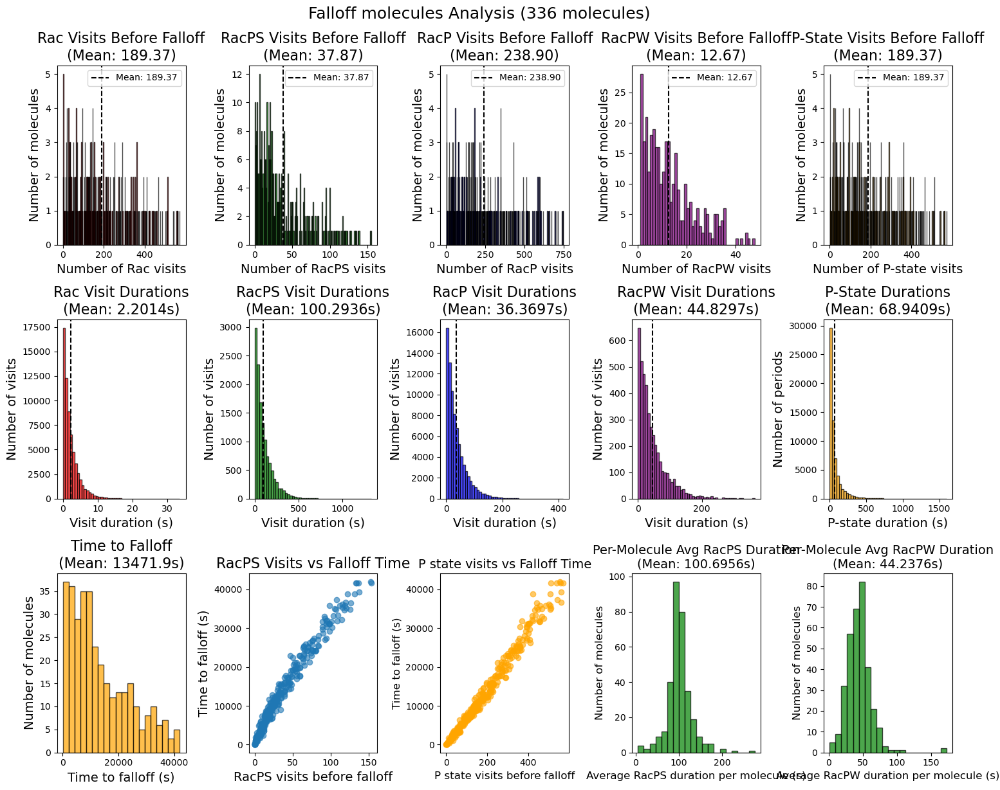

In [ ]:
# Create visualization for WT 
if tracked_molecules:
    create_falloff_analysis_plots(tracked_molecules)

Analyzing 60 unfallen molecules at t=43200.0s


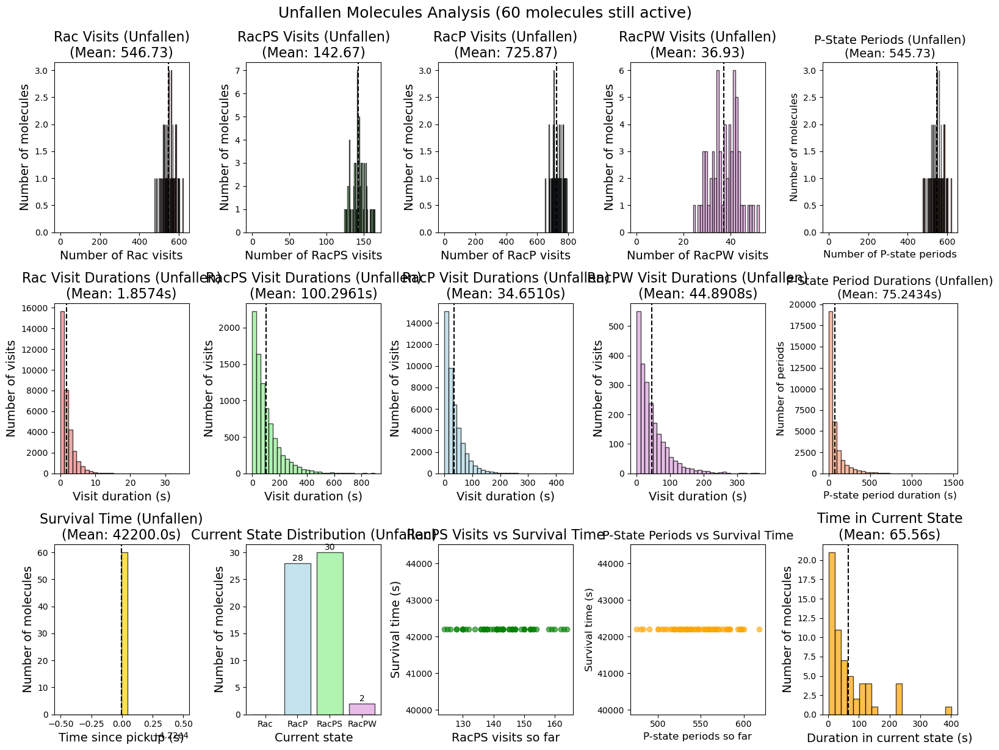


📊 UNFALLEN MOLECULES SUMMARY:
Total unfallen molecules: 60
Mean survival time: 42200.0s
Current state distribution:
  RacP: 28 molecules (46.7%)
  RacPS: 30 molecules (50.0%)
  RacPW: 2 molecules (3.3%)
Mean RacPS visits so far: 142.67
Mean RacPS visit duration: 100.2961s
Mean P-state periods so far: 545.73
Max P-state periods: 618
Mean P-state period duration: 75.2434s
Total completed P-state periods: 32744


In [223]:
# Create visualization for the unfallen molecules
if tracked_molecules:
    create_unfallen_analysis_plots(tracked_molecules, current_time = 3600*12)

In [21]:
## depletion of Sororin don't change Wapl residence

In [273]:
# Set up simulation, reaction rates 
# Stoichiometry matrix (reactions x species)
# Initial state: [Rac_free, Rac, RacP, RacPW, RacPS, S, W, P]
stoich = np.array([
    [0, -1, 1, 0, 0, 0, 0, -1],   # R1: Rac + P -> RacP
    [0, 1, -1, 0, 0, 0, 0, 1],    # R2: RacP -> Rac + P
    [0, 0, -1, 0, 1, -1, 0, 0],   # R3: RacP + S -> RacPS  
    [0, 0, 1, 0, -1, 1, 0, 0],    # R4: RacPS -> RacP + S
    [0, 0, -1, 1, 0, 0, -1, 0],   # R5: RacP + W -> RacPW
    [0, 0, 1, -1, 0, 0, 1, 0],    # R6: RacPW -> RacP + W
    [1, 0, 0, -1, 0, 0, 1, 1]     # R7: RacPW -> Rac_free + P + W
])

# Initial state: [Rac_free, Rac, RacP, RacPW, RacPS, S, W, P]
# initial = [0, 184667, 0, 0, 0, 54600, 29250, 294755]
# initial = [0, 18467, 0, 0, 0, 5460, 2925, 29476]
initial_dS = [0, 9234, 0, 0, 0, 2730*0.05, 1463, 14738]
# initial = [0, 1847, 0, 0, 0, 546, 293, 2948]
# initial = [0, 184, 0, 0, 0, 546*5, 293*5, 2948*5]

print("🎯 CALCULATING MEAN RacPS VISITS BEFORE FIRST FALLOFF")
print("=" * 60)
print("Strategy:")
print("1. Pick up all Rac molecules at t=1000s")
print("2. Track each molecule until it FIRST reaches Rac_free (falls off)")
print("3. Count RacPS visits that occur BEFORE the falloff")
print("4. Calculate mean RacPS visits for fallen off molecules only")
print("5. Ignore molecules that never fall off")
print("6. NEW: Calculate mean time spent in each state per visit")

# Run the analysis
#tracked_molecules_dS, final_time_dS  = track_rac_until_first_falloff(
#       rates, stoich, initial_dS, pickup_time = 1000, max_time = 3600*12)
tracked_molecules_dS, time_points_dS, snapshots_dS = track_rac_until_first_falloff_with_snapshots(
    rates, stoich, initial_dS, pickup_time = 1000, max_time = 12*3600, dt = 50)

🎯 CALCULATING MEAN RacPS VISITS BEFORE FIRST FALLOFF
Strategy:
1. Pick up all Rac molecules at t=1000s
2. Track each molecule until it FIRST reaches Rac_free (falls off)
3. Count RacPS visits that occur BEFORE the falloff
4. Calculate mean RacPS visits for fallen off molecules only
5. Ignore molecules that never fall off
6. NEW: Calculate mean time spent in each state per visit

🎯 PICKUP at t=1000.002s | 499 Rac molecules
  t=1142.3s | Active: 495 | Fallen off: 4
  t=1286.2s | Active: 492 | Fallen off: 7
  t=1429.3s | Active: 488 | Fallen off: 11
  t=1573.5s | Active: 481 | Fallen off: 18
  t=1719.5s | Active: 476 | Fallen off: 23
  t=1866.4s | Active: 473 | Fallen off: 26
  t=2012.9s | Active: 469 | Fallen off: 30
  t=2162.7s | Active: 466 | Fallen off: 33
  t=2313.8s | Active: 459 | Fallen off: 40
  t=2465.3s | Active: 457 | Fallen off: 42
  t=2618.3s | Active: 452 | Fallen off: 47
  t=2772.3s | Active: 445 | Fallen off: 54
  t=2929.4s | Active: 442 | Fallen off: 57
  t=3085.9s | Act

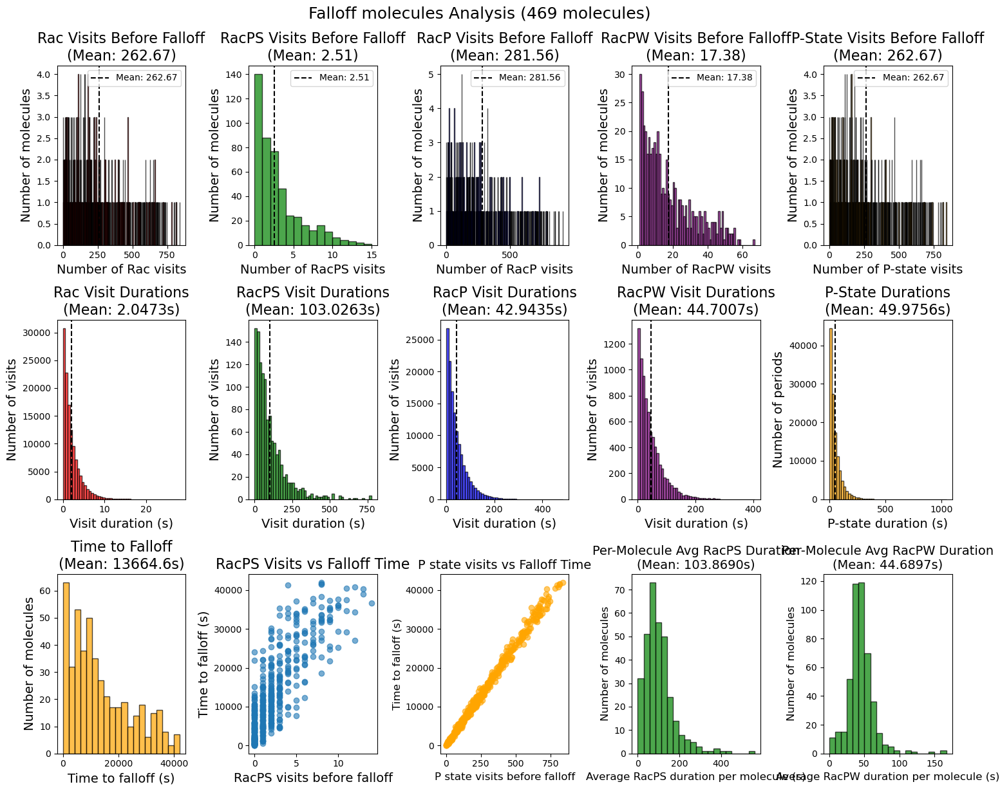

In [274]:
# Create visualization
if tracked_molecules_dS:
    create_falloff_analysis_plots(tracked_molecules_dS)

Analyzing 30 unfallen molecules at t=43200.0s


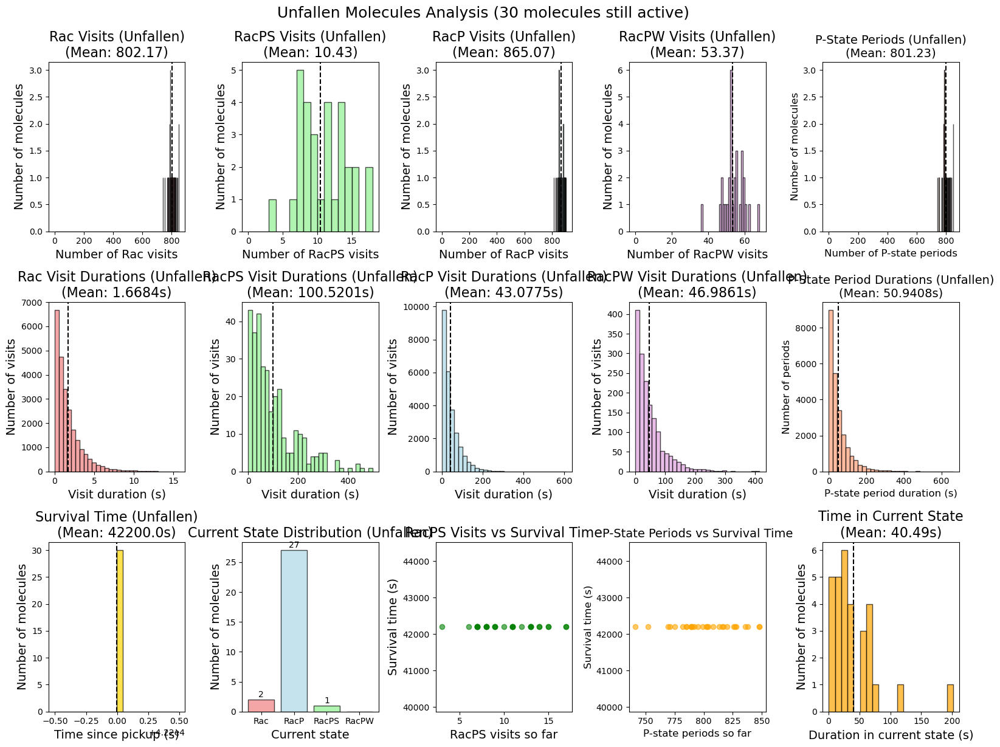


📊 UNFALLEN MOLECULES SUMMARY:
Total unfallen molecules: 30
Mean survival time: 42200.0s
Current state distribution:
  Rac: 2 molecules (6.7%)
  RacP: 27 molecules (90.0%)
  RacPS: 1 molecules (3.3%)
Mean RacPS visits so far: 10.43
Mean RacPS visit duration: 100.5201s
Mean P-state periods so far: 801.23
Max P-state periods: 848
Mean P-state period duration: 50.9408s
Total completed P-state periods: 24037


In [275]:
# Create visualization for the unfallen molecules
if tracked_molecules_dS:
    create_unfallen_analysis_plots(tracked_molecules_dS, current_time = 3600*12)

In [225]:
def plot_racps_vs_falloff(tracked_molecules, save_path="racps_vs_falloff.svg"):
    """Scatter plot of RacPS visits vs falloff time"""
    fallen_off_molecules = [mol for mol in tracked_molecules if mol['has_fallen_off']]
    
    if not fallen_off_molecules:
        print("No fallen off molecules to plot!")
        return
    
    racps_visits = [mol['visits_before_falloff']['RacPS'] for mol in fallen_off_molecules]
    falloff_times = [(mol['falloff_time']/3600 - mol['pickup_time']/3600) for mol in fallen_off_molecules]
    
    plt.figure(figsize=(6, 5))
    plt.scatter(racps_visits, falloff_times, alpha=0.6, color='#f47e20')
    # plt.title("RacPS Visits vs Falloff Time", fontsize=20)
    plt.xlabel(r"R$^{\mathrm{coh}}$PS visits before unbinding", fontsize=20)
    plt.ylabel("Time to unbind [h]", fontsize=20)
    plt.tick_params(axis='both', which='major', labelsize=20)
    plt.tight_layout()
    plt.savefig(save_path, format="svg")
    plt.close()
    print(f"Saved plot to {save_path}")


In [74]:
plot_racps_vs_falloff(tracked_molecules, save_path="racps_vs_falloff.svg")

Saved plot to racps_vs_falloff.svg


In [306]:
def plot_racpw_visit_durations(tracked_molecules, tracked_molecule_ds, save_path="racpw_visit_hist.svg"):
    """Plot RacPW visit durations for two sets of tracked molecules as overlaid histograms"""
    
    # Collect RacPW durations from the first dataset
    all_racpw_durations_1 = []
    for mol in tracked_molecules:
        all_racpw_durations_1.extend(mol['visit_durations']['RacPW'])
    
    # Collect RacPW durations from the second dataset
    all_racpw_durations_2 = []
    for mol in tracked_molecule_ds:
        all_racpw_durations_2.extend(mol['visit_durations']['RacPW'])
    
    if not all_racpw_durations_1 and not all_racpw_durations_2:
        print("No RacPW visit durations to plot!")
        return
    
    # Define common bins
    all_values = all_racpw_durations_1 + all_racpw_durations_2
    bins = np.linspace(min(all_values), max(all_values), 30)
    
    plt.figure(figsize=(7,6))
    plt.hist(all_racpw_durations_1, bins=bins, alpha=0.75, color='plum', edgecolor='black', label='WT', density=True)
    plt.hist(all_racpw_durations_2, bins=bins, alpha=0.75, color='lightgreen', edgecolor='black', label='dSororin', density=True)
    
    # Optional: vertical lines for means
    if all_racpw_durations_1:
        plt.axvline(np.mean(all_racpw_durations_1), color='plum', linestyle='--', label=f"Mean WT: {np.mean(all_racpw_durations_1):.1f}s")
    if all_racpw_durations_2:
        plt.axvline(np.mean(all_racpw_durations_2), color='green', linestyle='--', label=f"Mean dSororin: {np.mean(all_racpw_durations_2):.1f}s")
    
    plt.xlabel(r"R$^{\mathrm{coh}}$PW Visit Duration [s]", fontsize=20)
    plt.ylabel("Number of Visits [Normalized]", fontsize=20)
    plt.tick_params(axis='both', which='major', labelsize=20)
    plt.legend(fontsize=16)
    plt.tight_layout()
    plt.savefig(save_path, format="svg")
    plt.close()
    print(f"Saved plot to {save_path}")


In [308]:
plot_racpw_visit_durations(tracked_molecules, tracked_molecules_dS, save_path="racpw_visit_hist.svg")

Saved plot to racpw_visit_hist.svg


In [295]:
tracked_molecules

[{'id': 0,
  'current_state': 'Rac_free',
  'pickup_time': 1000.0037982369248,
  'visits_before_falloff': {'Rac': 133, 'RacP': 151, 'RacPS': 15, 'RacPW': 4},
  'current_visit_start': {'Rac': None,
   'RacP': None,
   'RacPS': None,
   'RacPW': None},
  'visit_durations': {'Rac': [1.5556571053449488,
    9.75003543316484,
    0.6171581863804931,
    1.865225473517512,
    0.6673656554128229,
    0.9258794580857739,
    4.212308922106786,
    4.5700724737153,
    0.7074375110917117,
    5.317544804681802,
    0.17108637375145008,
    3.4319753094443968,
    1.2919701984312724,
    1.8886343940976076,
    0.5455083325259693,
    1.55340366800624,
    0.06489452675555185,
    1.9914129800563387,
    0.8415380501537584,
    1.3851240826159028,
    4.722651547405576,
    1.4707209187824901,
    1.7748686581469428,
    2.8034119757753615,
    7.6913517035081895,
    1.6456651783705638,
    2.769980197744644,
    5.294812331031608,
    8.201923373397676,
    1.9054729990457417,
    5.477140657

In [323]:
def plot_p_state_durations(tracked_molecules, tracked_molecules_dS, save_path):
    """Plot P-state durations for two sets of tracked molecules as overlaid histograms"""
    
    # Collect P-state durations from the first dataset
    all_p_durations_1 = []
    for mol in tracked_molecules:
        all_p_durations_1.extend(mol['p_state_durations'])
    
    # Collect P-state durations from the second dataset
    all_p_durations_2 = []
    for mol in tracked_molecules_dS:
        all_p_durations_2.extend(mol['p_state_durations'])
    
    if not all_p_durations_1 and not all_p_durations_2:
        print("No P-state visit durations to plot!")
        return
    
    # Define common bins
    all_values = all_p_durations_1 + all_p_durations_2
    bins = np.linspace(0, max(all_values), 100)
    
    # Create figure
    plt.figure(figsize=(7,6))
    plt.hist(all_p_durations_1, bins=bins, alpha=0.75, color='#859ED7', 
             edgecolor='black', label='WT', density=True)
    plt.hist(all_p_durations_2, bins=bins, alpha=0.75, color='#8F69C5', 
             edgecolor='black', label='dSororin', density=True)
    
    # Add mean lines
    if all_p_durations_1:
        plt.axvline(np.mean(all_p_durations_1), color='#859ED7', linestyle='--',
                    label=f"Mean WT: {np.mean(all_p_durations_1):.1f}s")
    if all_p_durations_2:
        plt.axvline(np.mean(all_p_durations_2), color='#8F69C5', linestyle='--',
                    label=f"Mean dWapl: {np.mean(all_p_durations_2):.1f}s")
    
    # Labels and formatting
    plt.xlabel("P-state duration [s]", fontsize=20)
    plt.ylabel("Number of periods [Normalized]", fontsize=20)
    plt.xlim(0, 400) 
    plt.tick_params(axis='both', which='major', labelsize=18)
    plt.legend(fontsize=14)
    plt.tight_layout()
    
    # Save figure
    plt.savefig(save_path, format="svg")
    plt.close()
    print(f"Saved plot to {save_path}")


In [340]:
def plot_p_state_durations_all(tracked_molecules, tracked_molecules_dS, tracked_molecules_dW, save_path):
    """Plot P-state durations for two sets of tracked molecules as overlaid histograms"""
    
    # Collect P-state durations from the first dataset
    all_p_durations_1 = []
    for mol in tracked_molecules:
        all_p_durations_1.extend(mol['p_state_durations'])
    
    # Collect P-state durations from the second dataset
    all_p_durations_2 = []
    for mol in tracked_molecules_dS:
        all_p_durations_2.extend(mol['p_state_durations'])
    
    all_p_durations_3 = []
    for mol in tracked_molecules_dW:
        all_p_durations_3.extend(mol['p_state_durations'])
    
    if not all_p_durations_1 and not all_p_durations_2 and not all_p_durations_3:
        print("No P-state visit durations to plot!")
        return
    
    # Define common bins
    all_values = all_p_durations_1 + all_p_durations_2 +  all_p_durations_3
    bins = np.linspace(0, max(all_values), 100)
    
    # Create figure
    plt.figure(figsize=(7,6))
    plt.hist(all_p_durations_1, bins=bins, alpha=0.75, color='#859ED7', 
             edgecolor='black', label='WT', density=True)
    plt.hist(all_p_durations_2, bins=bins, alpha=0.75, color='#F8AB61', 
             edgecolor='black', label='dSororin', density=True)
    plt.hist(all_p_durations_3, bins=bins, alpha=0.75, color='#8F69C5', 
             edgecolor='black', label='dWapl', density=True)
    
    # Add mean lines
    if all_p_durations_1:
        plt.axvline(np.mean(all_p_durations_1), color='#859ED7', linestyle='--',
                    label=f"Mean WT: {np.mean(all_p_durations_1):.1f}s")
    if all_p_durations_2:
        plt.axvline(np.mean(all_p_durations_2), color='#F8AB61', linestyle='--',
                    label=f"Mean dSororin: {np.mean(all_p_durations_2):.1f}s")
    if all_p_durations_3:
        plt.axvline(np.mean(all_p_durations_3), color='#8F69C5', linestyle='--',
                    label=f"Mean dWapl: {np.mean(all_p_durations_3):.1f}s")
    
    # Labels and formatting
    plt.xlabel("P-state duration [s]", fontsize=20)
    plt.ylabel("Number of periods [Normalized]", fontsize=20)
    plt.xlim(0, 400) 
    plt.tick_params(axis='both', which='major', labelsize=18)
    plt.legend(fontsize=14)
    plt.tight_layout()
    
    # Save figure
    plt.savefig(save_path, format="svg")
    plt.close()
    print(f"Saved plot to {save_path}")


In [341]:
plot_p_state_durations_all(tracked_molecules, tracked_molecules_dS, tracked_molecules_dW, save_path="p_state_durations_all.svg")

Saved plot to p_state_durations_all.svg


In [315]:
# Set up simulation, reaction rates 
# Stoichiometry matrix (reactions x species)
# Initial state: [Rac_free, Rac, RacP, RacPW, RacPS, S, W, P]
stoich = np.array([
    [0, -1, 1, 0, 0, 0, 0, -1],   # R1: Rac + P -> RacP
    [0, 1, -1, 0, 0, 0, 0, 1],    # R2: RacP -> Rac + P
    [0, 0, -1, 0, 1, -1, 0, 0],   # R3: RacP + S -> RacPS  
    [0, 0, 1, 0, -1, 1, 0, 0],    # R4: RacPS -> RacP + S
    [0, 0, -1, 1, 0, 0, -1, 0],   # R5: RacP + W -> RacPW
    [0, 0, 1, -1, 0, 0, 1, 0],    # R6: RacPW -> RacP + W
    [1, 0, 0, -1, 0, 0, 1, 1]     # R7: RacPW -> Rac_free + P + W
])

# Initial state: [Rac_free, Rac, RacP, RacPW, RacPS, S, W, P]
# initial = [0, 184667, 0, 0, 0, 54600, 29250, 294755]
# initial = [0, 18467, 0, 0, 0, 5460, 2925, 29476]
initial_dW = [0, 9234, 0, 0, 0, 2730, 1463*0.05, 14738]
# initial = [0, 1847, 0, 0, 0, 546, 293, 2948]
# initial = [0, 184, 0, 0, 0, 546*5, 293*5, 2948*5]

print("🎯 CALCULATING MEAN RacPS VISITS BEFORE FIRST FALLOFF")
print("=" * 60)
print("Strategy:")
print("1. Pick up all Rac molecules at t=1000s")
print("2. Track each molecule until it FIRST reaches Rac_free (falls off)")
print("3. Count RacPS visits that occur BEFORE the falloff")
print("4. Calculate mean RacPS visits for fallen off molecules only")
print("5. Ignore molecules that never fall off")
print("6. NEW: Calculate mean time spent in each state per visit")

# Run the analysis
#tracked_molecules_dS, final_time_dS  = track_rac_until_first_falloff(
#       rates, stoich, initial_dS, pickup_time = 1000, max_time = 3600*12)
tracked_molecules_dW, time_points_dW, snapshots_dW = track_rac_until_first_falloff_with_snapshots(
    rates, stoich, initial_dW, pickup_time = 1000, max_time = 12*3600, dt = 50)

🎯 CALCULATING MEAN RacPS VISITS BEFORE FIRST FALLOFF
Strategy:
1. Pick up all Rac molecules at t=1000s
2. Track each molecule until it FIRST reaches Rac_free (falls off)
3. Count RacPS visits that occur BEFORE the falloff
4. Calculate mean RacPS visits for fallen off molecules only
5. Ignore molecules that never fall off
6. NEW: Calculate mean time spent in each state per visit

🎯 PICKUP at t=1000.001s | 457 Rac molecules
  t=1150.0s | Active: 457 | Fallen off: 0
  t=1299.6s | Active: 456 | Fallen off: 1
  t=1449.9s | Active: 456 | Fallen off: 1
  t=1600.0s | Active: 456 | Fallen off: 1
  t=1751.4s | Active: 456 | Fallen off: 1
  t=1902.6s | Active: 456 | Fallen off: 1
  t=2053.8s | Active: 456 | Fallen off: 1
  t=2206.1s | Active: 456 | Fallen off: 1
  t=2356.1s | Active: 456 | Fallen off: 1
  t=2507.2s | Active: 456 | Fallen off: 1
  t=2658.5s | Active: 456 | Fallen off: 1
  t=2809.3s | Active: 456 | Fallen off: 1
  t=2962.1s | Active: 456 | Fallen off: 1
  t=3111.7s | Active: 455 | 

In [322]:
plot_p_state_durations(tracked_molecules, tracked_molecules_dW, save_path="p_state_durations_dW.svg")

Saved plot to p_state_durations_dW.svg


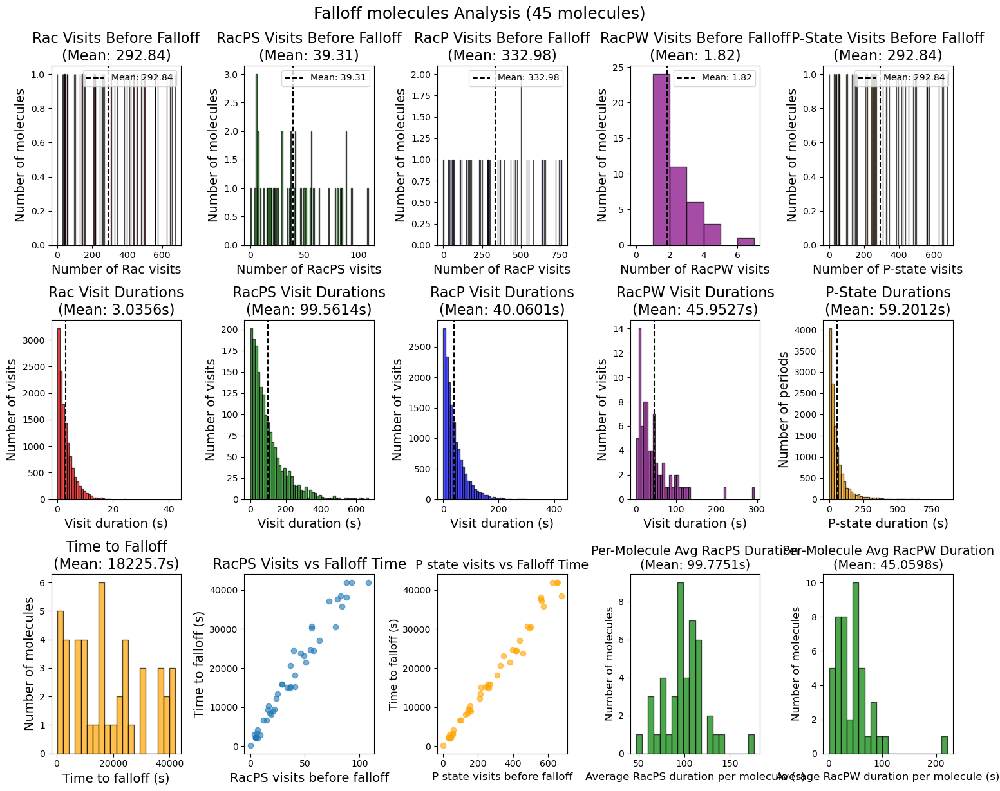

In [318]:
# Create visualization
if tracked_molecules_dW:
    create_falloff_analysis_plots(tracked_molecules_dW)

Analyzing 412 unfallen molecules at t=43200.0s


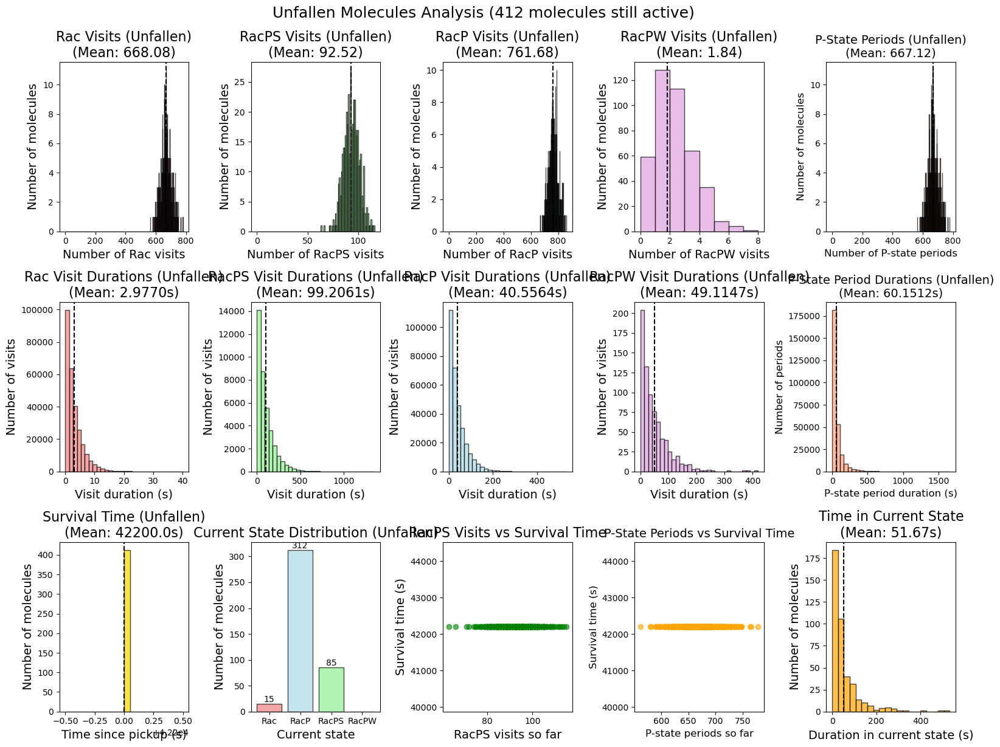


📊 UNFALLEN MOLECULES SUMMARY:
Total unfallen molecules: 412
Mean survival time: 42200.0s
Current state distribution:
  Rac: 15 molecules (3.6%)
  RacP: 312 molecules (75.7%)
  RacPS: 85 molecules (20.6%)
Mean RacPS visits so far: 92.52
Mean RacPS visit duration: 99.2061s
Mean P-state periods so far: 667.12
Max P-state periods: 778
Mean P-state period duration: 60.1512s
Total completed P-state periods: 274853


In [321]:
# Create visualization for the unfallen molecules
if tracked_molecules_dW:
    create_unfallen_analysis_plots(tracked_molecules_dW, current_time = 3600*12)

In [358]:
def plot_racpw_visits_all(tracked_molecules, tracked_molecules_dS, tracked_molecules_dW, save_path):
    """Plot RacPW visits before falloff for WT, dSororin, and dWapl as overlaid histograms"""
    
    # Filter active molecules
    unfallen_molecules   = [mol for mol in tracked_molecules    if mol['status'] == 'still_active']
    unfallen_molecules_dS = [mol for mol in tracked_molecules_dS if mol['status'] == 'still_active']
    unfallen_molecules_dW = [mol for mol in tracked_molecules_dW if mol['status'] == 'still_active']
    
    # Collect RacPW visits before falloff
    racpw_visits_1 = [mol['visits_before_falloff']['RacPW'] for mol in unfallen_molecules]
    racpw_visits_2 = [mol['visits_before_falloff']['RacPW'] for mol in unfallen_molecules_dS]
    racpw_visits_3 = [mol['visits_before_falloff']['RacPW'] for mol in unfallen_molecules_dW]
    
    if not racpw_visits_1 and not racpw_visits_2 and not racpw_visits_3:
        print("No RacPW visits to plot!")
        return
    
    # Define common integer bins
    all_values = racpw_visits_1 + racpw_visits_2 + racpw_visits_3
    bins = np.arange(0, max(all_values) + 2) - 0.5
    
    # Create figure
    plt.figure(figsize=(7,6))
    plt.hist(racpw_visits_1, bins=bins, alpha=0.75, color='#859ED7',
             edgecolor='black', label='WT', density=True)
    plt.hist(racpw_visits_2, bins=bins, alpha=0.75, color='#F8AB61',
             edgecolor='black', label='dSororin', density=True)
    plt.hist(racpw_visits_3, bins=bins, alpha=0.75, color='#8F69C5',
             edgecolor='black', label='dWapl', density=True)
    
    # Add mean lines
    if racpw_visits_1:
        plt.axvline(np.mean(racpw_visits_1), color='#859ED7', linestyle='--',
                    label=f"Mean WT: {np.mean(racpw_visits_1):.1f}")
    if racpw_visits_2:
        plt.axvline(np.mean(racpw_visits_2), color='#F8AB61', linestyle='--',
                    label=f"Mean dSororin: {np.mean(racpw_visits_2):.1f}")
    if racpw_visits_3:
        plt.axvline(np.mean(racpw_visits_3), color='#8F69C5', linestyle='--',
                    label=f"Mean dWapl: {np.mean(racpw_visits_3):.1f}")
    
    # Labels and formatting
    plt.xlabel(r"Number of R$^{\mathrm{coh}}$PW visits before falloff", fontsize=20)
    plt.ylabel("Probability [Normalized]", fontsize=20)
    plt.xlim(left=0)
    plt.tick_params(axis='both', which='major', labelsize=18)
    plt.legend(fontsize=14)
    plt.tight_layout()
    
    # Save figure
    plt.savefig(save_path, format="svg")
    plt.close()
    print(f"Saved plot to {save_path}")

In [359]:
plot_racpw_visits_all(tracked_molecules, tracked_molecules_dS, tracked_molecules_dW, save_path="racpw_visit_hist.svg")

Saved plot to racpw_visit_hist.svg


In [271]:
def plot_bound_species(time_points, snapshots, filename):
    """
    Plot total bound Rac, Rac_free, S, W, and P over time and save as SVG.

    Parameters
    ----------
    time_points : list or array
        Time points of the snapshots in seconds.
    snapshots : list of dicts
        Each dict contains counts of all species at the corresponding time.
    filename : str
        Filename to save the SVG figure.
    """
    if not snapshots:
        print("No snapshots to plot!")
        return

    time_h = [t / 3600 for t in time_points]  # convert to hours

    # Compute total Rac at each snapshot
    total_rac = [snap['Rac_free'] + snap['Rac'] + snap['RacP'] + snap['RacPW'] + snap['RacPS'] for snap in snapshots]
    total_W = [snap['RacPW']  + snap['W'] for snap in snapshots]
    total_S = [snap['RacPS']  + snap['S'] for snap in snapshots]
    total_P = [snap['RacP'] + snap['RacPW'] + snap['RacPS'] +  snap['P'] for snap in snapshots]

    # Normalize each species by total Rac
    total_bound_rac_norm = [(snap['Rac'] + snap['RacP'] + snap['RacPW'] + snap['RacPS']) / t for snap, t in zip(snapshots, total_rac)]
    rac_free_norm = [snap['Rac_free'] / t for snap, t in zip(snapshots, total_rac)]
    S_norm = [snap['S'] / t for snap, t in zip(snapshots, total_S)]
    W_norm = [snap['W'] / t for snap, t in zip(snapshots, total_W)]
    P_norm = [snap['P'] / t for snap, t in zip(snapshots, total_P)]

    plt.figure(figsize=(8, 4))
    # plt.plot(time_h, total_bound_rac_norm, label='Total Bound Rac', color='blue',lw=2)
    plt.plot(time_h, rac_free_norm, label=r'$\mathrm{R_{free}} / \mathrm{R_{total}}$', color='#2b6a99', lw=2)
    plt.plot(time_h, S_norm, label=r'[S] / S$_{\mathrm{total}}$', color='green', lw=2)
    plt.plot(time_h, W_norm, label=r'[W] / W$_{\mathrm{total}}$', color='#f16c23', lw=2)
    plt.plot(time_h, P_norm, label=r'[P] / P$_{\mathrm{total}}$', color='purple', lw=2)

    plt.xlabel("Time [h]", fontsize=20)
    plt.ylabel("Fraction of free molecules", fontsize=18)
    plt.tick_params(axis='both', labelsize=20)
    # plt.title("Normalized species counts over time", fontsize=16)
    plt.legend(fontsize=18)
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(filename, format="svg", dpi=300, bbox_inches="tight")
    plt.show()


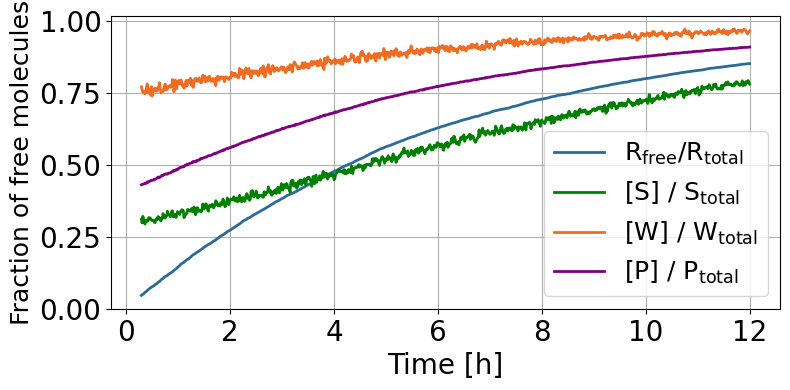

In [272]:
plot_bound_species(time_points, snapshots, filename="bound_species.svg")

In [100]:
def plot_aggregated_bound_counts(tracked_molecules_over_time, time_points, save_path=None):
    """
    Plot aggregated counts of molecules over time based on custom categories and optionally save as SVG.
    """
    import matplotlib.pyplot as plt

    bounded_P = []
    bounded_S = []
    bounded_W = []
    bounded_R = []

    for molecules in tracked_molecules_over_time:
        states = [mol['current_state'] for mol in molecules]
        # Count each category
        count_Rac = states.count('Rac')
        count_RacP = states.count('RacP')
        count_RacPS = states.count('RacPS')
        count_RacPW = states.count('RacPW')

        bounded_P.append(count_RacP + count_RacPS + count_RacPW)
        bounded_S.append(count_RacPS)
        bounded_W.append(count_RacPW)
        bounded_R.append(count_Rac + count_RacP + count_RacPS + count_RacPW)

    # Plot
    plt.figure(figsize=(8,5))
    plt.plot(time_points, bounded_P, label='Bounded P', marker='o')
    plt.plot(time_points, bounded_S, label='Bounded S', marker='s')
    plt.plot(time_points, bounded_W, label='Bounded W', marker='^')
    plt.plot(time_points, bounded_R, label='Bounded R', marker='x')

    plt.xlabel('Time [s]', fontsize=14)
    plt.ylabel('Number of molecules', fontsize=14)
    plt.title('Aggregated Bound Molecules Over Time', fontsize=16)
    plt.legend()
    plt.tight_layout()

    # Save figure if path provided
    if save_path is not None:
        plt.savefig(save_path, format='svg')



In [ ]:
plot_aggregated_bound_counts(tracked_molecules, time_points, save_path=None)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

def exponential_pdf(x, rate):
    """Exponential probability density function"""
    return rate * np.exp(-rate * x)

def analyze_exponential_fits(tracked_molecules, rates):
    """
    Analyze if visit durations follow exponential distribution and compare with theory
    
    Parameters:
    - tracked_molecules: list of molecule dictionaries from your simulation
    - rates: array of reaction rates [k1, k2, k3, k4, k5, k6, k7]
    """
    
    print(f"\n🧪 EXPONENTIAL DISTRIBUTION ANALYSIS")
    print("=" * 80)
    
    fallen_off_molecules = [mol for mol in tracked_molecules if mol['has_fallen_off']]
    
    # Define theoretical residence times (1/k_off) - simplified version
    # These are the basic exit rates for each state
    theoretical_residence_times = {
        'Rac': "Variable (depends on [P])",  # Will calculate empirically
        'RacP': "Variable (depends on [S], [W])",  # Will calculate empirically  
        'RacPS': 1.0 / rates[3],  # k_off_S (R4: RacPS -> RacP + S)
        'RacPW': 1.0 / (rates[5] + rates[6])  # k_off_W + k_falloff (R6 + R7)
    }
    
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    
    results = {}
    
    for i, state_name in enumerate(['Rac', 'RacP', 'RacPS', 'RacPW']):
        # Collect all visit durations for this state
        all_durations = []
        for mol in fallen_off_molecules:
            all_durations.extend(mol['visit_durations'][state_name])
        
        if not all_durations:
            print(f"{state_name}: No visits recorded")
            continue
            
        all_durations = np.array(all_durations)
        
        # Calculate empirical statistics
        measured_mean = np.mean(all_durations)
        measured_std = np.std(all_durations)
        
        # Get theoretical mean (only for states where we can calculate it)
        if isinstance(theoretical_residence_times[state_name], str):
            theoretical_mean = measured_mean  # Use measured as "theoretical" for comparison
            theoretical_note = theoretical_residence_times[state_name]
        else:
            theoretical_mean = theoretical_residence_times[state_name]
            theoretical_note = f"1/k_off = {theoretical_mean:.6f}s"
        
        # Fit exponential distribution
        # Method 1: Maximum likelihood estimation (rate = 1/mean)
        fitted_rate_mle = 1.0 / measured_mean
        
        # Method 2: Scipy curve fitting
        try:
            # Create histogram for fitting
            hist_counts, bin_edges = np.histogram(all_durations, bins=50, density=True)
            bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
            
            # Fit exponential
            popt, pcov = curve_fit(exponential_pdf, bin_centers, hist_counts, 
                                 p0=[fitted_rate_mle], maxfev=5000)
            fitted_rate_scipy = popt[0]
            fitted_rate_error = np.sqrt(pcov[0,0])
            
        except Exception as e:
            fitted_rate_scipy = fitted_rate_mle
            fitted_rate_error = np.nan
        
        # Kolmogorov-Smirnov test for exponential distribution
        ks_stat, ks_pvalue = stats.kstest(all_durations, 
                                        lambda x: 1 - np.exp(-fitted_rate_mle * x))
        
        # Store results
        results[state_name] = {
            'measured_mean': measured_mean,
            'theoretical_mean': theoretical_mean if not isinstance(theoretical_residence_times[state_name], str) else None,
            'theoretical_note': theoretical_note,
            'fitted_rate_mle': fitted_rate_mle,
            'fitted_rate_scipy': fitted_rate_scipy,
            'fitted_rate_error': fitted_rate_error,
            'ks_stat': ks_stat,
            'ks_pvalue': ks_pvalue,
            'n_visits': len(all_durations),
            'relative_error': abs(measured_mean - theoretical_mean) / theoretical_mean * 100 if not isinstance(theoretical_residence_times[state_name], str) else None
        }
        
        # Plot histogram and fitted exponential
        axes[0, i].hist(all_durations, bins=50, density=True, alpha=0.7, 
                       color='skyblue', edgecolor='black', label='Data')
        
        # Plot theoretical exponential (only for states where we have theory)
        x_theory = np.linspace(0, np.max(all_durations), 1000)
        if not isinstance(theoretical_residence_times[state_name], str):
            theoretical_rate = 1.0 / theoretical_mean
            y_theory = exponential_pdf(x_theory, theoretical_rate)
            axes[0, i].plot(x_theory, y_theory, 'r-', linewidth=2, 
                           label=f'Theory (λ={theoretical_rate:.3f})')
        
        # Plot fitted exponential
        y_fitted = exponential_pdf(x_theory, fitted_rate_mle)
        axes[0, i].plot(x_theory, y_fitted, 'g--', linewidth=2, 
                       label=f'Fitted (λ={fitted_rate_mle:.3f})')
        
        title_text = f'{state_name} Visit Durations\n'
        if not isinstance(theoretical_residence_times[state_name], str):
            title_text += f'Theory: {theoretical_mean:.6f}s\n'
        title_text += f'Measured: {measured_mean:.6f}s'
        
        axes[0, i].set_title(title_text)
        axes[0, i].set_xlabel('Duration (s)')
        axes[0, i].set_ylabel('Probability Density')
        axes[0, i].legend()
        axes[0, i].grid(True, alpha=0.3)
        
        # Q-Q plot for exponential distribution
        # Generate theoretical quantiles
        n = len(all_durations)
        uniform_quantiles = np.arange(1, n+1) / (n+1)
        theoretical_quantiles = -np.log(1 - uniform_quantiles) / fitted_rate_mle
        empirical_quantiles = np.sort(all_durations)
        
        axes[1, i].scatter(theoretical_quantiles, empirical_quantiles, alpha=0.6)
        min_val = min(np.min(theoretical_quantiles), np.min(empirical_quantiles))
        max_val = max(np.max(theoretical_quantiles), np.max(empirical_quantiles))
        axes[1, i].plot([min_val, max_val], [min_val, max_val], 'r-', linewidth=2)
        axes[1, i].set_title(f'{state_name} Q-Q Plot\\n'
                           f'KS p-value: {ks_pvalue:.4f}')
        axes[1, i].set_xlabel('Theoretical Quantiles')
        axes[1, i].set_ylabel('Empirical Quantiles')
        axes[1, i].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Print detailed results
    print(f"\n📊 EXPONENTIAL FIT RESULTS:")
    print("=" * 80)
    print(f"{'State':<8} {'Theory':<12} {'Measured':<12} {'Error %':<8} {'KS p-val':<10} {'n visits':<10}")
    print("-" * 80)
    
    for state_name in ['Rac', 'RacP', 'RacPS', 'RacPW']:
        if state_name in results:
            r = results[state_name]
            if r['theoretical_mean'] is not None:
                theory_str = f"{r['theoretical_mean']:.6f}"
                error_str = f"{r['relative_error']:.1f}"
            else:
                theory_str = "Variable"
                error_str = "N/A"
            
            print(f"{state_name:<8} {theory_str:<12} {r['measured_mean']:<12.6f} "
                  f"{error_str:<8} {r['ks_pvalue']:<10.4f} {r['n_visits']:<10d}")
        else:
            print(f"{state_name:<8} {'No data':<12} {'No data':<12} {'N/A':<8} {'N/A':<10} {'0':<10}")
    
    print(f"\n📋 RATE CONSTANTS USED:")
    print("=" * 80)
    print(f"rates[3] (RacPS -> RacP + S): {rates[3]:.6f} s⁻¹")
    print(f"rates[5] (RacPW -> RacP + W): {rates[5]:.6f} s⁻¹") 
    print(f"rates[6] (RacPW -> falloff):  {rates[6]:.6f} s⁻¹")
    print(f"RacPS theoretical residence time: {1.0/rates[3]:.6f} s")
    print(f"RacPW theoretical residence time: {1.0/(rates[5] + rates[6]):.6f} s")
    
    print(f"\\n📈 INTERPRETATION:")
    print("=" * 80)
    print("• Theoretical mean = 1/k_off (residence time)")
    print("• Good fit: KS p-value > 0.05 and error < 5%")
    print("• Error % = |measured - theoretical| / theoretical * 100%")
    print("• Q-Q plots should show points along diagonal for exponential distribution")
    
    # Check if any fits are particularly bad
    bad_fits = []
    for state_name, r in results.items():
        if r['ks_pvalue'] < 0.05:
            bad_fits.append(f"{state_name} (p={r['ks_pvalue']:.3f})")
    
    if bad_fits:
        print(f"\n⚠️  POOR EXPONENTIAL FITS: {', '.join(bad_fits)}")
        print("KS p-value < 0.05 suggests non-exponential distribution")
    else:
        print(f"\n✅ ALL VISIT DURATIONS APPEAR EXPONENTIALLY DISTRIBUTED!")
    
    # Check theoretical predictions
    good_predictions = []
    for state_name, r in results.items():
        if r['relative_error'] is not None and r['relative_error'] < 5:
            good_predictions.append(state_name)
    
    if good_predictions:
        print(f"✅ GOOD THEORETICAL PREDICTIONS: {', '.join(good_predictions)} (<5% error)")
    
    return results

# Example usage:
"""
# After running your simulation:
tracked_molecules, final_time = track_rac_until_first_falloff(rates, stoich_matrix, initial_state)

# Run exponential analysis 
results = analyze_exponential_fits(tracked_molecules, rates)
"""

'\n# After running your simulation:\ntracked_molecules, final_time = track_rac_until_first_falloff(rates, stoich_matrix, initial_state)\n\n# Run exponential analysis \nresults = analyze_exponential_fits(tracked_molecules, rates)\n'


🧪 EXPONENTIAL DISTRIBUTION ANALYSIS


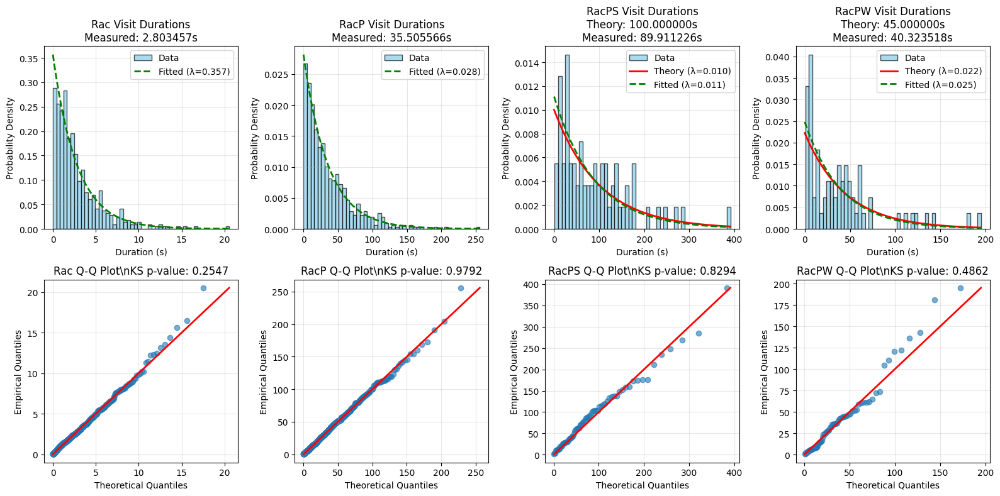


📊 EXPONENTIAL FIT RESULTS:
State    Theory       Measured     Error %  KS p-val   n visits  
--------------------------------------------------------------------------------
Rac      Variable     2.803457     N/A      0.2547     524       
RacP     Variable     35.505566    N/A      0.9792     623       
RacPS    100.000000   89.911226    10.1     0.8294     70        
RacPW    45.000000    40.323518    10.4     0.4862     70        

📋 RATE CONSTANTS USED:
rates[3] (RacPS -> RacP + S): 0.010000 s⁻¹
rates[5] (RacPW -> RacP + W): 0.021126 s⁻¹
rates[6] (RacPW -> falloff):  0.001096 s⁻¹
RacPS theoretical residence time: 100.000000 s
RacPW theoretical residence time: 45.000000 s
\n📈 INTERPRETATION:
• Theoretical mean = 1/k_off (residence time)
• Good fit: KS p-value > 0.05 and error < 5%
• Error % = |measured - theoretical| / theoretical * 100%
• Q-Q plots should show points along diagonal for exponential distribution

✅ ALL VISIT DURATIONS APPEAR EXPONENTIALLY DISTRIBUTED!


In [ ]:
results = analyze_exponential_fits(tracked_molecules, rates)

In [ ]:
def analyze_falloff_statistics_FIXED(tracked_molecules, pickup_time, end_time):
    """Analyze statistics for molecules that fell off - FIXED for list input"""
    print(f"\n📊 FALLOFF ANALYSIS")
    print("=" * 80)
    
    # FIXED: Handle list input instead of dictionary
    if isinstance(tracked_molecules, dict):
        molecules_list = list(tracked_molecules.values())
    else:
        molecules_list = tracked_molecules
    
    fallen_off_molecules = [mol for mol in molecules_list if mol['has_fallen_off']]
    still_active = [mol for mol in molecules_list if mol['status'] == 'still_active']
    
    total_molecules = len(molecules_list)
    falloff_count = len(fallen_off_molecules)
    
    print(f"Total molecules tracked: {total_molecules}")
    print(f"✅ Fell off (reached Rac_free): {falloff_count} ({falloff_count/total_molecules*100:.1f}%)")
    print(f"⏳ Still active at end: {len(still_active)} ({len(still_active)/total_molecules*100:.1f}%)")
    
    if not fallen_off_molecules:
        print("\nNo molecules fell off yet - need longer simulation time!")
        return
    
    # Calculate visit statistics for fallen off molecules ONLY
    rac_visits_before_falloff = [mol['visits_before_falloff']['Rac'] for mol in fallen_off_molecules]
    racps_visits_before_falloff = [mol['visits_before_falloff']['RacPS'] for mol in fallen_off_molecules]
    racp_visits_before_falloff = [mol['visits_before_falloff']['RacP'] for mol in fallen_off_molecules]
    racpw_visits_before_falloff = [mol['visits_before_falloff']['RacPW'] for mol in fallen_off_molecules]
    
    mean_rac_visits = np.mean(rac_visits_before_falloff)
    mean_racps_visits = np.mean(racps_visits_before_falloff)
    std_racps_visits = np.std(racps_visits_before_falloff)
    mean_racp_visits = np.mean(racp_visits_before_falloff)
    mean_racpw_visits = np.mean(racpw_visits_before_falloff)
    
    # Calculate falloff times
    falloff_times = [(mol['falloff_time'] - mol['pickup_time']) for mol in fallen_off_molecules]
    mean_falloff_time = np.mean(falloff_times)
    
    print(f"\n🎯 KEY RESULT - MEAN VISITS BEFORE FIRST FALLOFF:")
    print(f"Mean Rac visits:  {mean_rac_visits:.3f}")
    print(f"Mean RacPS visits: {mean_racps_visits:.3f} ± {std_racps_visits:.3f}")
    print(f"Mean RacP visits:  {mean_racp_visits:.3f}")
    print(f"Mean RacPW visits: {mean_racpw_visits:.3f}")
    print(f"Range RacPS: {min(racps_visits_before_falloff)} - {max(racps_visits_before_falloff)} visits")
    
    # Calculate visit duration statistics
    print(f"\n⏱️  MEAN TIME SPENT PER VISIT (only fallen off molecules):")
    print("=" * 80)
    
    for state_name in ['Rac', 'RacP', 'RacPS', 'RacPW']:
        # Collect all visit durations for this state from all fallen off molecules
        all_durations = []
        for mol in fallen_off_molecules:
            all_durations.extend(mol['visit_durations'][state_name])
        
        if all_durations:
            mean_duration = np.mean(all_durations)
            std_duration = np.std(all_durations)
            median_duration = np.median(all_durations)
            total_visits = len(all_durations)
            
            print(f"{state_name:6s}: {mean_duration:.6f}s ± {std_duration:.6f}s "
                  f"(median: {median_duration:.6f}s, n={total_visits} visits)")
        else:
            print(f"{state_name:6s}: No visits recorded")
    
    return fallen_off_molecules

def analyze_unfallen_statistics_FIXED(tracked_molecules, pickup_time, end_time):
    """Analyze statistics for molecules that are still active - FIXED for list input"""
    print(f"\n📊 UNFALLEN MOLECULES ANALYSIS")
    print("=" * 80)
    
    # FIXED: Handle list input instead of dictionary
    if isinstance(tracked_molecules, dict):
        molecules_list = list(tracked_molecules.values())
    else:
        molecules_list = tracked_molecules
    
    fallen_off_molecules = [mol for mol in molecules_list if mol['has_fallen_off']]
    unfallen_molecules = [mol for mol in molecules_list if mol['status'] == 'still_active']
    
    total_molecules = len(molecules_list)
    unfallen_count = len(unfallen_molecules)
    
    print(f"Total molecules tracked: {total_molecules}")
    print(f"⏳ Still active at end: {unfallen_count} ({unfallen_count/total_molecules*100:.1f}%)")
    print(f"✅ Fell off: {len(fallen_off_molecules)} ({len(fallen_off_molecules)/total_molecules*100:.1f}%)")
    
    if not unfallen_molecules:
        print("\nNo unfallen molecules to analyze!")
        return
    
    # Analyze current state distribution of unfallen molecules
    current_states = {}
    for mol in unfallen_molecules:
        state = mol['current_state']
        current_states[state] = current_states.get(state, 0) + 1
    
    print(f"\n🎯 CURRENT STATE DISTRIBUTION (unfallen molecules):")
    for state, count in current_states.items():
        percentage = count / unfallen_count * 100
        print(f"{state:6s}: {count:4d} molecules ({percentage:.1f}%)")
    
    # Calculate visit statistics for unfallen molecules
    rac_visits = [mol['visits_before_falloff']['Rac'] for mol in unfallen_molecules]
    racps_visits = [mol['visits_before_falloff']['RacPS'] for mol in unfallen_molecules]
    racp_visits = [mol['visits_before_falloff']['RacP'] for mol in unfallen_molecules]
    racpw_visits = [mol['visits_before_falloff']['RacPW'] for mol in unfallen_molecules]
    
    print(f"\n🎯 VISIT STATISTICS (unfallen molecules so far):")
    if rac_visits:
        print(f"Mean Rac visits:  {np.mean(rac_visits):.3f} ± {np.std(rac_visits):.3f}")
    if racps_visits:
        print(f"Mean RacPS visits: {np.mean(racps_visits):.3f} ± {np.std(racps_visits):.3f}")
    if racp_visits:
        print(f"Mean RacP visits:  {np.mean(racp_visits):.3f} ± {np.std(racp_visits):.3f}")
    if racpw_visits:
        print(f"Mean RacPW visits: {np.mean(racpw_visits):.3f} ± {np.std(racpw_visits):.3f}")
    
    # Calculate survival times (time active so far)
    survival_times = [(end_time - mol['pickup_time']) for mol in unfallen_molecules]
    mean_survival_time = np.mean(survival_times)
    
    print(f"\nMean survival time so far: {mean_survival_time:.3f}s")
    
    return unfallen_molecules

def analyze_exponential_fits_FIXED(tracked_molecules, rates):
    """
    Analyze if visit durations follow exponential distribution - FIXED for list input
    """
    
    print(f"\n🧪 EXPONENTIAL DISTRIBUTION ANALYSIS")
    print("=" * 80)
    
    # FIXED: Handle list input instead of dictionary
    if isinstance(tracked_molecules, dict):
        molecules_list = list(tracked_molecules.values())
    else:
        molecules_list = tracked_molecules
    
    fallen_off_molecules = [mol for mol in molecules_list if mol['has_fallen_off']]
    
    if not fallen_off_molecules:
        print("No fallen off molecules to analyze!")
        return
    
    # Define theoretical residence times (1/k_off) - simplified version
    theoretical_residence_times = {
        'Rac': "Variable (depends on [P])",
        'RacP': "Variable (depends on [S], [W])",
        'RacPS': 1.0 / rates[3],  # k_off_S (R4: RacPS -> RacP + S)
        'RacPW': 1.0 / (rates[5] + rates[6])  # k_off_W + k_falloff (R6 + R7)
    }
    
    results = {}
    
    print(f"\n📊 EXPONENTIAL FIT RESULTS:")
    print("=" * 80)
    print(f"{'State':<8} {'Theory':<12} {'Measured':<12} {'Error %':<8} {'n visits':<10}")
    print("-" * 70)
    
    for state_name in ['Rac', 'RacP', 'RacPS', 'RacPW']:
        # Collect all visit durations for this state
        all_durations = []
        for mol in fallen_off_molecules:
            all_durations.extend(mol['visit_durations'][state_name])
        
        if not all_durations:
            print(f"{state_name:<8} {'No data':<12} {'No data':<12} {'N/A':<8} {'0':<10}")
            continue
            
        all_durations = np.array(all_durations)
        measured_mean = np.mean(all_durations)
        
        # Get theoretical mean
        if isinstance(theoretical_residence_times[state_name], str):
            theory_str = "Variable"
            error_str = "N/A"
        else:
            theoretical_mean = theoretical_residence_times[state_name]
            theory_str = f"{theoretical_mean:.6f}"
            relative_error = abs(measured_mean - theoretical_mean) / theoretical_mean * 100
            error_str = f"{relative_error:.1f}"
        
        print(f"{state_name:<8} {theory_str:<12} {measured_mean:<12.6f} "
              f"{error_str:<8} {len(all_durations):<10d}")
        
        results[state_name] = {
            'measured_mean': measured_mean,
            'n_visits': len(all_durations)
        }
    
    print(f"\n📋 RATE CONSTANTS USED:")
    print("=" * 80)
    print(f"rates[3] (RacPS -> RacP + S): {rates[3]:.6f} s⁻¹")
    print(f"rates[5] (RacPW -> RacP + W): {rates[5]:.6f} s⁻¹") 
    print(f"rates[6] (RacPW -> falloff):  {rates[6]:.6f} s⁻¹")
    print(f"RacPS theoretical residence time: {1.0/rates[3]:.6f} s")
    print(f"RacPW theoretical residence time: {1.0/(rates[5] + rates[6]):.6f} s")
    
    return results

In [ ]:
fallen_off = analyze_falloff_statistics_FIXED(tracked_molecules, pickup_time=3600, end_time=3600*18)
unfallen = analyze_unfallen_statistics_FIXED(tracked_molecules, pickup_time=3600, end_time=3600*18)
results = analyze_exponential_fits_FIXED(tracked_molecules, rates)


📊 FALLOFF ANALYSIS
Total molecules tracked: 410
✅ Fell off (reached Rac_free): 41 (10.0%)
⏳ Still active at end: 369 (90.0%)

🎯 KEY RESULT - MEAN VISITS BEFORE FIRST FALLOFF:
Mean Rac visits:  12.780
Mean RacPS visits: 1.707 ± 1.452
Mean RacP visits:  15.195
Mean RacPW visits: 1.707
Range RacPS: 0 - 5 visits

⏱️  MEAN TIME SPENT PER VISIT (only fallen off molecules):
Rac   : 2.803457s ± 2.764607s (median: 1.948529s, n=524 visits)
RacP  : 35.505566s ± 34.850692s (median: 25.351456s, n=623 visits)
RacPS : 89.911226s ± 76.798399s (median: 72.102030s, n=70 visits)
RacPW : 40.323518s ± 41.935463s (median: 30.350821s, n=70 visits)

📊 UNFALLEN MOLECULES ANALYSIS
Total molecules tracked: 410
⏳ Still active at end: 369 (90.0%)
✅ Fell off: 41 (10.0%)

🎯 CURRENT STATE DISTRIBUTION (unfallen molecules):
RacPW :   15 molecules (4.1%)
RacP  :  259 molecules (70.2%)
RacPS :   75 molecules (20.3%)
Rac   :   20 molecules (5.4%)

🎯 VISIT STATISTICS (unfallen molecules so far):
Mean Rac visits:  26.287 